# Atividade 3 — Processamento de Linguagem Natural (PLN)

Resolução das **cinco questões da lista 3**, usando a mesma base de tweets das Atividades 1 e 2: agrupamento com k-means e silhueta, projeções t-SNE, busca semântica com word2vec, classificação com LSTM e Conv1D e análise linguística com spaCy e grafos.

**Integrantes:**

- José Anderson da Silva
- Otto Tenório de Albuquerque Lins Bisneto

Execute as células em ordem, com a pasta de trabalho em `atividade_3`. As dependências e as instruções para execução local ou no Colab estão no `README.md`. O modelo word2vec é baixado na primeira execução; o modelo inglês `en_core_web_lg` também é necessário. Os resultados são gravados em `resultados/questao_1` até `resultados/questao_5`.

# Preparação da base

**Base de dados:** o mesmo `Tweets.csv` da [Twitter US Airline Sentiment (Kaggle)](https://www.kaggle.com/datasets/drnimishadavis/twitter-us-airline-sentiment) usado nas Atividades 1 e 2.

**Pré-processamento:** a lista 3 pede a base "após os pré-processamentos realizados na lista 1". Reproduzimos, sem alterações, a função `preprocessar_texto` da Questão 5 da Atividade 1 (a mesma usada na Atividade 2): remoção de palavras com dígitos, minúsculas, remoção de pontuação e tokenização por espaços. Tweets que ficam vazios são excluídos. A Questão 3 acrescenta a remoção de stopwords e o filtro por vocabulário do modelo, como o próprio enunciado exige.

In [1]:
import os
# Limita a concorrência para evitar excesso de threads em BLAS/OpenMP.
for variavel in ['OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS']:
    os.environ.setdefault(variavel, '4')

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

caminho_base = next(
    (p for p in [Path('dados/Tweets.csv'), Path('Tweets.csv')] if p.is_file()),
    None,
)
if caminho_base is not None:
    tweets = pd.read_csv(caminho_base, dtype={'tweet_id': 'string'})
else:
    # No Colab, permite selecionar o CSV no computador.
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Coloque Tweets.csv na pasta dados ou ao lado do notebook.')
    from io import BytesIO
    enviados = files.upload()
    if 'Tweets.csv' not in enviados:
        raise FileNotFoundError('Selecione o arquivo Tweets.csv e execute novamente.')
    tweets = pd.read_csv(BytesIO(enviados['Tweets.csv']), dtype={'tweet_id': 'string'})

print(f'Registros carregados: {len(tweets)}')
display(tweets[['tweet_id', 'airline', 'airline_sentiment', 'text']].head())

Registros carregados: 14640


,tweet_id,airline,airline_sentiment,text
0,570306133677760513,Virgin America,neutral,@VirginAmerica What @dhepburn said.
1,570301130888122368,Virgin America,positive,@VirginAmerica plus you've added commercials t...
2,570301083672813571,Virgin America,neutral,@VirginAmerica I didn't today... Must mean I n...
3,570301031407624196,Virgin America,negative,@VirginAmerica it's really aggressive to blast...
4,570300817074462722,Virgin America,negative,@VirginAmerica and it's a really big bad thing...


In [2]:
import string
import unicodedata

def preprocessar_texto(texto):
    # Reproduz, sem alterações, o pré-processamento da Questão 5 da Atividade 1.
    # 1. Remove o elemento inteiro se ele contiver algum dígito.
    sem_numeros = [palavra for palavra in texto.split()
                   if not any(c.isdigit() for c in palavra)]
    # 2. Converte para minúsculas.
    minusculo = ' '.join(sem_numeros).lower()
    # 3. Apaga pontuação ASCII e Unicode.
    sem_pontuacao = ''.join(
        c for c in minusculo
        if c not in string.punctuation
        and not unicodedata.category(c).startswith('P')
    )
    # 4. Tokeniza em palavras.
    return sem_pontuacao.split()

tweets['tokens'] = tweets['text'].map(preprocessar_texto)
tweets['texto_processado'] = tweets['tokens'].map(' '.join)

base = tweets[tweets['texto_processado'].str.len() > 0].reset_index(drop=True)
print(f'Textos vazios após o pré-processamento (excluídos): {len(tweets) - len(base)}')
print(f'Base final: {len(base)} tweets')

pasta_resultados = Path('resultados')
pasta_q1 = pasta_resultados / 'questao_1'
pasta_q2 = pasta_resultados / 'questao_2'
pasta_q3 = pasta_resultados / 'questao_3'
for pasta in [pasta_q1, pasta_q2, pasta_q3]:
    pasta.mkdir(parents=True, exist_ok=True)

SEMENTE = 42

Textos vazios após o pré-processamento (excluídos): 0
Base final: 14640 tweets


# Questão 1 — k-means e coeficiente de silhueta

**Enunciado:** agrupar os dados com k-means, procurando um valor adequado de k pelo coeficiente de silhueta médio, e plotar k (eixo horizontal) contra a silhueta média (eixo vertical), para (a) a representação TF-IDF e (b) a representação dos documentos no espaço latente do método clássico de modelagem de tópicos da lista anterior.

**Método de tópicos:** o enunciado fala na "questão 5 da lista anterior", mas na lista 2 a modelagem de tópicos é a Questão 3. Entendemos que se trata dela e usamos o **NMF com 8 tópicos** que escolhemos lá (mesmos hiperparâmetros). A representação latente de cada documento é a linha correspondente da matriz `W` do NMF (documento × tópico), com 8 dimensões.

**Distância:** o `KMeans` do scikit-learn minimiza distâncias euclidianas quadráticas; a avaliação pela silhueta usa a distância do cosseno. O TF-IDF e as linhas de `W` são normalizados para norma 1. Para dois vetores unitários, a distância euclidiana ao quadrado é duas vezes a distância do cosseno, mas os centroides do K-means não são necessariamente unitários. Portanto, este procedimento **não é equivalente ao K-means esférico (por cosseno)**. A normalização reduz o efeito da magnitude dos vetores; o critério usado para escolher k continua sendo a silhueta com cosseno.

**Silhueta:** a silhueta exata de cada documento exige a distância a todos os outros (cerca de 214 milhões de pares). Como os vetores têm norma 1, a distância média de um documento a um grupo se calcula com a soma dos vetores do grupo (`1 − x·S/n`), o que dá o mesmo valor exato sem montar a matriz de distâncias. A função é conferida contra `sklearn.metrics.silhouette_score(metric='cosine')` abaixo.

In [3]:
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

vetor_tfidf = TfidfVectorizer()
X_tfidf = vetor_tfidf.fit_transform(base['texto_processado'])

# Mesmo NMF da Questão 3 da Atividade 2 (k = 8 tópicos).
modelo_nmf = NMF(n_components=8, random_state=SEMENTE, init='nndsvda', max_iter=400)
W_nmf = modelo_nmf.fit_transform(X_tfidf)
X_nmf = normalize(W_nmf)

print(f'TF-IDF: {X_tfidf.shape[0]} documentos x {X_tfidf.shape[1]} termos')
print(f'NMF (espaço latente): {X_nmf.shape[0]} documentos x {X_nmf.shape[1]} tópicos')
print(f'Documentos com vetor latente nulo (nenhum tópico ativo): {int((W_nmf.sum(axis=1) == 0).sum())}')

TF-IDF: 14640 documentos x 13196 termos
NMF (espaço latente): 14640 documentos x 8 tópicos
Documentos com vetor latente nulo (nenhum tópico ativo): 0


In [4]:
def silhueta_cosseno(X, rotulos):
    # Silhueta de cada documento com distância do cosseno, exata, para linhas de norma 1 (ou 0).
    # dist(i, j) = 1 - x_i . x_j, logo a soma das distâncias de i a um grupo c é n_c - x_i . S_c,
    # com S_c a soma dos vetores do grupo.
    n = len(rotulos)
    k = int(rotulos.max()) + 1
    indicador = sparse.csr_matrix((np.ones(n), (np.arange(n), rotulos)), shape=(n, k))
    somas = indicador.T @ X
    produtos = X @ somas.T
    produtos = produtos.toarray() if sparse.issparse(produtos) else np.asarray(produtos)
    if sparse.issparse(X):
        quadrados = np.asarray(X.multiply(X).sum(axis=1)).ravel()
    else:
        quadrados = (X * X).sum(axis=1)

    tamanhos = np.bincount(rotulos, minlength=k)
    soma_dist = tamanhos[None, :] - produtos
    linhas = np.arange(n)

    # a(i): média sobre os demais documentos do próprio grupo (retira a distância de i a si mesmo).
    proprio = soma_dist[linhas, rotulos] - (1 - quadrados)
    a = proprio / np.maximum(tamanhos[rotulos] - 1, 1)

    # b(i): menor média entre os outros grupos.
    medias = np.where(tamanhos > 0, soma_dist / np.maximum(tamanhos, 1), np.inf)
    medias[linhas, rotulos] = np.inf
    b = medias.min(axis=1)

    denominador = np.maximum(a, b)
    s = np.divide(b - a, denominador, out=np.zeros(n), where=denominador > 0)
    s[tamanhos[rotulos] == 1] = 0  # convenção do scikit-learn para grupos unitários
    return s

# Conferência contra o scikit-learn (k = 8), em blocos para limitar a memória.
from sklearn import config_context
for nome, X in [('NMF', X_nmf), ('TF-IDF', X_tfidf)]:
    rot = KMeans(n_clusters=8, n_init=10, random_state=SEMENTE).fit_predict(X)
    propria = silhueta_cosseno(X, rot).mean()
    with config_context(working_memory=256):
        referencia = silhouette_score(X, rot, metric='cosine')
    print(f'{nome}: silhueta própria = {propria:.6f} | scikit-learn = {referencia:.6f}')
    assert abs(propria - referencia) < 1e-6

NMF: silhueta própria = 0.483150 | scikit-learn = 0.483150


TF-IDF: silhueta própria = 0.008238 | scikit-learn = 0.008238


In [5]:
import time

valores_k = list(range(2, 31))

def varrer_k(X, nome):
    linhas, rotulos_por_k = [], {}
    for k in valores_k:
        t0 = time.perf_counter()
        rot = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE).fit_predict(X)
        s = silhueta_cosseno(X, rot)
        rotulos_por_k[k] = rot
        linhas.append({'k': k, 'silhueta_media': float(s.mean()),
                       'menor_grupo': int(np.bincount(rot).min()),
                       'maior_grupo': int(np.bincount(rot).max())})
        print(f'{nome}: k={k:2d}, silhueta={s.mean():.4f}, {time.perf_counter() - t0:.1f}s', flush=True)
    return pd.DataFrame(linhas), rotulos_por_k

sil_tfidf, rotulos_tfidf = varrer_k(X_tfidf, 'tfidf')
sil_nmf, rotulos_nmf = varrer_k(X_nmf, 'nmf')

sil_tfidf.to_csv(pasta_q1 / 'silhueta_tfidf.csv', index=False, encoding='utf-8-sig')
sil_nmf.to_csv(pasta_q1 / 'silhueta_nmf.csv', index=False, encoding='utf-8-sig')
print('--- TF-IDF ---')
display(sil_tfidf.round(4))
print('--- NMF (espaço latente) ---')
display(sil_nmf.round(4))

tfidf: k= 2, silhueta=0.0068, 0.3s


tfidf: k= 3, silhueta=0.0079, 0.4s


tfidf: k= 4, silhueta=0.0066, 0.4s


tfidf: k= 5, silhueta=0.0123, 0.4s


tfidf: k= 6, silhueta=0.0141, 0.6s


...

nmf: k=30, silhueta=0.3869, 0.2s


--- TF-IDF ---


,k,silhueta_media,menor_grupo,maior_grupo
0,2,0.0068,1989,12651
1,3,0.0079,410,12098
2,4,0.0066,374,8622
3,5,0.0123,343,6054
4,6,0.0141,331,3735
5,7,0.0085,145,5088
6,8,0.0082,315,5155
7,9,0.0112,145,6259
8,10,0.0116,145,4013
9,11,0.0109,145,3717


--- NMF (espaço latente) ---


,k,silhueta_media,menor_grupo,maior_grupo
0,2,0.2511,6378,8262
1,3,0.3166,2300,6641
2,4,0.3620,1858,5415
3,5,0.3762,1680,4286
4,6,0.4127,1484,3965
5,7,0.4556,1081,3752
6,8,0.4831,1054,3446
7,9,0.4408,1049,2762
8,10,0.4249,1041,2118
9,11,0.4193,751,1953


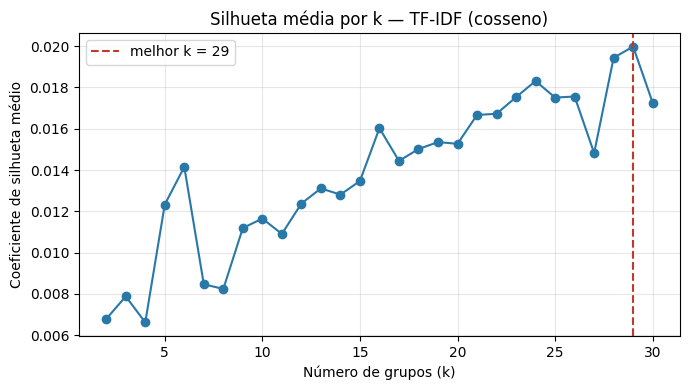

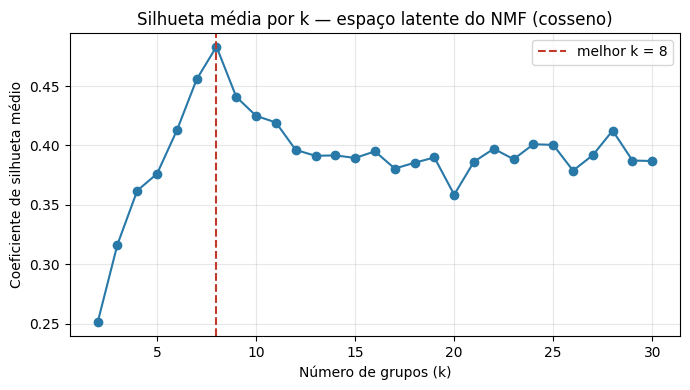

1a) TF-IDF: k = 29, silhueta média = 0.0200
1b) NMF:    k = 8, silhueta média = 0.4831

Tamanho dos grupos (TF-IDF): [199, 583, 432, 205, 1439, 359, 519, 323, 391, 517, 335, 629, 334, 1053, 390, 967, 272, 415, 329, 1046, 174, 1059, 235, 187, 612, 145, 217, 616, 658]

Tamanho dos grupos (NMF): [1920, 2039, 1764, 1358, 1364, 3446, 1695, 1054]


In [6]:
def plotar_silhueta(tabela, titulo, arquivo):
    k_melhor = int(tabela.loc[tabela['silhueta_media'].idxmax(), 'k'])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(tabela['k'], tabela['silhueta_media'], marker='o', color='#2878A8')
    ax.axvline(k_melhor, color='#C0392B', linestyle='--', label=f'melhor k = {k_melhor}')
    ax.set_xlabel('Número de grupos (k)')
    ax.set_ylabel('Coeficiente de silhueta médio')
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(pasta_q1 / arquivo, dpi=160)
    plt.show()
    return k_melhor

k_tfidf = plotar_silhueta(sil_tfidf, 'Silhueta média por k — TF-IDF (cosseno)', 'silhueta_tfidf.png')
k_nmf = plotar_silhueta(sil_nmf, 'Silhueta média por k — espaço latente do NMF (cosseno)', 'silhueta_nmf.png')

grupos_tfidf = rotulos_tfidf[k_tfidf]
grupos_nmf = rotulos_nmf[k_nmf]
print(f'1a) TF-IDF: k = {k_tfidf}, silhueta média = {sil_tfidf.set_index("k").loc[k_tfidf, "silhueta_media"]:.4f}')
print(f'1b) NMF:    k = {k_nmf}, silhueta média = {sil_nmf.set_index("k").loc[k_nmf, "silhueta_media"]:.4f}')

pd.DataFrame({
    'indice_base': np.arange(len(base)), 'tweet_id': base['tweet_id'],
    'grupo_tfidf': grupos_tfidf, 'grupo_nmf': grupos_nmf,
}).to_csv(pasta_q1 / 'grupos.csv', index=False, encoding='utf-8-sig')

for nome, grupos in [('TF-IDF', grupos_tfidf), ('NMF', grupos_nmf)]:
    print(f'\nTamanho dos grupos ({nome}): {np.bincount(grupos).tolist()}')

**Resultados e análise (Questão 1).**

- **TF-IDF (1a):** a maior silhueta média no intervalo de 2 a 30 grupos foi **0,0200 em k = 29**. Os valores variaram entre 0,0066 e 0,0200; essa faixa próxima de zero indica pouca separação segundo a distância do cosseno. O máximo próximo ao limite da grade não sustenta, por si só, um número natural de grupos. Escolhemos o melhor k testado para prosseguir na questão 2, reconhecendo essa limitação. Tweets curtos geram vetores esparsos; palavras funcionais e nomes de companhias têm bastante influência, como mostram os termos por grupo abaixo.
- **Espaço latente do NMF (1b):** a maior silhueta foi **0,4831 em k = 8**. O pico coincide com os oito tópicos do modelo: nesse espaço, o agrupamento recupera principalmente a estrutura induzida pelos tópicos. Os valores de silhueta dos dois espaços não devem ser tratados como prova de superioridade semântica do NMF, pois as representações têm dimensões e geometrias distintas.
- A implementação de silhueta coincidiu com a referência do scikit-learn nas duas representações, com tolerância de 10⁻⁶. O agrupamento usa K-means euclidiano; o critério de avaliação é a silhueta com cosseno.

In [7]:
# Palavras de maior peso no centróide de cada grupo (apoio à interpretação).
vocab = np.array(vetor_tfidf.get_feature_names_out())
for nome, grupos in [('TF-IDF', grupos_tfidf), ('NMF', grupos_nmf)]:
    print(f'--- Grupos de {nome}: 6 termos de maior peso médio no TF-IDF ---')
    for g in range(grupos.max() + 1):
        media = np.asarray(X_tfidf[grupos == g].mean(axis=0)).ravel()
        print(f'  grupo {g:2d} ({(grupos == g).sum():5d} docs): {", ".join(vocab[media.argsort()[::-1][:6]])}')

--- Grupos de TF-IDF: 6 termos de maior peso médio no TF-IDF ---
  grupo  0 (  199 docs): seat, my, to, on, flight, the
  grupo  1 (  583 docs): to, from, flight, on, united, delayed
  grupo  2 (  432 docs): will, be, you, united, to, the
  grupo  3 (  205 docs): thanks, jetblue, americanair, united, usairways, southwestair
  grupo  4 ( 1439 docs): united, you, to, and, the, for
  grupo  5 (  359 docs): gate, at, the, to, for, agent
  grupo  6 (  519 docs): get, to, on, me, can, and
  grupo  7 (  323 docs): as, to, united, the, my, americanair
  grupo  8 (  391 docs): virginamerica, to, the, you, is, for
  grupo  9 (  517 docs): customer, service, your, to, united, the
  grupo 10 (  335 docs): bag, my, to, united, is, in
  grupo 11 (  629 docs): the, on, to, of, plane, is
  grupo 12 (  334 docs): please, me, to, help, you, usairways
  grupo 13 ( 1053 docs): jetblue, to, you, the, for, is
  grupo 14 (  390 docs): out, of, to, the, you, and
  grupo 15 (  967 docs): usairways, to, you, an

# Questão 2 — Projeção multidimensional com t-SNE

**Enunciado:** (a) t-SNE sobre o TF-IDF, colorindo pelos grupos da 1a; (b) variar a `perplexity` e discutir; (c) t-SNE sobre os vetores da 1b, encontrar bons valores de `perplexity` e plotar a melhor projeção de cada método, colorindo as duas projeções finais pelos grupos da 1b.

**Implementação:**

- Antes do t-SNE, reduzimos o TF-IDF a 50 dimensões com SVD truncado (`TruncatedSVD`) e normalizamos as linhas, para reduzir o custo computacional. Essa é uma aproximação da representação TF-IDF: a fração de variância preservada é exibida abaixo. Nos itens a e b, as cores são os grupos da 1a; no item c, usamos os grupos da 1b nas duas projeções, conforme solicitado.
- Os vetores já têm norma 1, então a distância euclidiana ordena os pares como o cosseno. Usamos `metric='euclidean'`, `init='pca'` e `learning_rate='auto'`.
- A projeção final é feita com todos os documentos, com `random_state=42`.

In [8]:
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE, trustworthiness

svd = TruncatedSVD(n_components=50, random_state=SEMENTE)
Z_tfidf = normalize(svd.fit_transform(X_tfidf))
print(f'Variância explicada pelas 50 componentes do SVD: {svd.explained_variance_ratio_.sum():.3f}')

cache_tsne = {}

def projetar(nome, Z, perplexidade):
    chave = (nome, perplexidade)
    if chave not in cache_tsne:
        t0 = time.perf_counter()
        modelo = TSNE(n_components=2, perplexity=perplexidade, init='pca', learning_rate='auto',
                      random_state=SEMENTE, n_jobs=-1)
        cache_tsne[chave] = modelo.fit_transform(Z)
        print(f'  t-SNE {nome}, perplexity={perplexidade}: {time.perf_counter() - t0:.0f}s, '
              f'KL = {modelo.kl_divergence_:.3f}')
    return cache_tsne[chave]

def plotar_projecao(ax, emb, rotulos, titulo):
    grupos = np.unique(rotulos)
    n = len(grupos)
    if n <= 10:
        paleta = plt.get_cmap('tab10')(np.arange(n))
    elif n <= 20:
        paleta = plt.get_cmap('tab20')(np.arange(n))
    else:
        paleta = plt.get_cmap('turbo')(np.linspace(0, 1, n))
    ax.scatter(emb[:, 0], emb[:, 1], c=paleta[rotulos], s=3, linewidths=0, alpha=0.7, rasterized=True)
    for g in grupos:
        x, y = np.median(emb[rotulos == g], axis=0)
        ax.text(x, y, str(g), fontsize=9, weight='bold', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.75, lw=0))
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

Variância explicada pelas 50 componentes do SVD: 0.175


**a) t-SNE sobre o TF-IDF**, com a perplexidade padrão do scikit-learn (30), colorido pelos grupos da 1a.

  t-SNE tfidf, perplexity=30: 68s, KL = 3.123


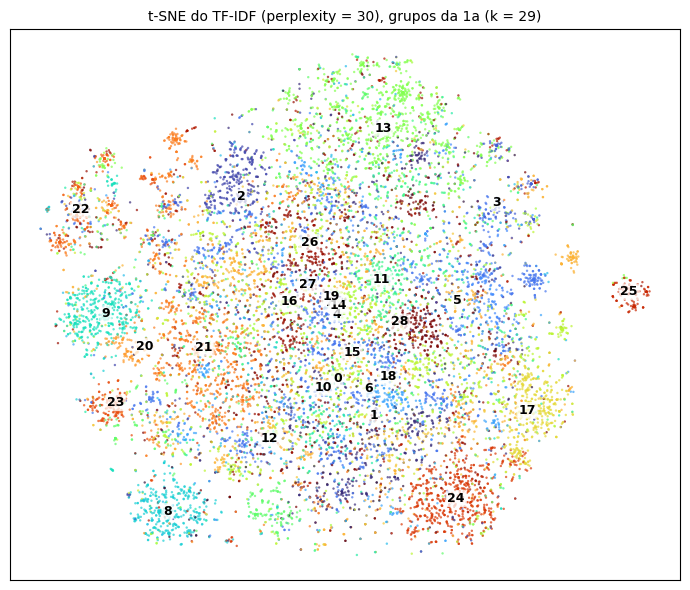

In [9]:
emb = projetar('tfidf', Z_tfidf, 30)
fig, ax = plt.subplots(figsize=(7, 6))
plotar_projecao(ax, emb, grupos_tfidf, f't-SNE do TF-IDF (perplexity = 30), grupos da 1a (k = {k_tfidf})')
fig.tight_layout()
fig.savefig(pasta_q2 / 'tsne_tfidf_perplexity30.png', dpi=160)
plt.show()

**b) Variação da perplexidade** (valores menores e maiores que o padrão 30), no mesmo experimento da 2a.

  t-SNE tfidf, perplexity=5: 38s, KL = 2.803


  t-SNE tfidf, perplexity=100: 72s, KL = 2.971


  t-SNE tfidf, perplexity=300: 120s, KL = 2.580


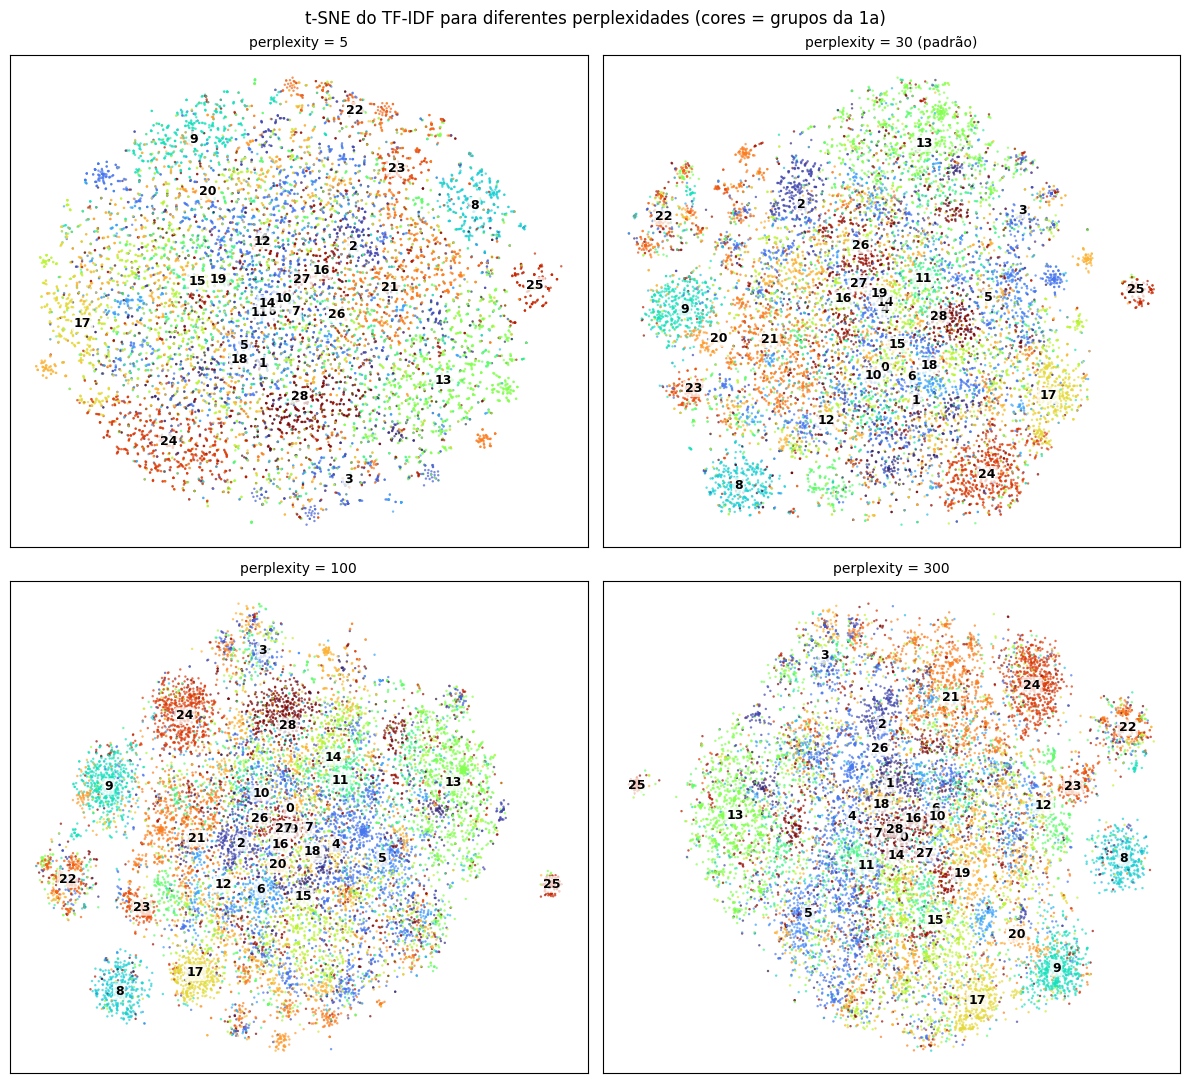

In [10]:
perplexidades_b = [5, 30, 100, 300]
fig, eixos = plt.subplots(2, 2, figsize=(12, 11))
for ax, p in zip(eixos.ravel(), perplexidades_b):
    plotar_projecao(ax, projetar('tfidf', Z_tfidf, p), grupos_tfidf, f'perplexity = {p}' + (' (padrão)' if p == 30 else ''))
fig.suptitle('t-SNE do TF-IDF para diferentes perplexidades (cores = grupos da 1a)')
fig.tight_layout()
fig.savefig(pasta_q2 / 'tsne_tfidf_perplexidades.png', dpi=130)
plt.show()

**Resultado da 2a e análise da 2b (perplexidade).** O gráfico da 2a usa perplexidade 30 e as cores dos grupos da 1a. A figura de quatro painéis mantém a representação, os rótulos e a semente e altera apenas a perplexidade entre 5, 30, 100 e 300.

Uma perplexidade menor concentra a definição de vizinhança em relações mais locais; valores maiores consideram vizinhanças efetivamente mais amplas. O parâmetro não equivale a um número fixo de vizinhos. No painel de 5, aparecem muitos pequenos agrupamentos; em 30, algumas ilhas tornam-se mais reconhecíveis. Nos painéis de 100 e 300, mudam o formato, a separação e o tamanho aparente das regiões, sem eliminar a mistura entre vários grupos. Assim, uma separação visual pode depender bastante do parâmetro e não comprova que os grupos sejam bem separados no espaço original.

A silhueta baixa do TF-IDF na questão 1 é uma evidência adicional dessa limitação. As coordenadas, orientações e distâncias entre ilhas de painéis diferentes não têm correspondência direta. Também não escolhemos a perplexidade pela menor divergência KL: essa quantidade depende das afinidades definidas pelo próprio parâmetro.

**c) Escolha da perplexidade e comparação dos dois métodos.**

Para escolher a perplexidade de forma objetiva, usamos a **confiabilidade** (`trustworthiness`, scikit-learn), que penaliza vizinhos introduzidos na projeção, ponderando-os pela posição no ranking de distâncias no espaço de origem (aqui, 15 vizinhos). Seu valor varia de 0 a 1; quanto maior, menor essa distorção local. Ela é calculada para os dois métodos sobre a mesma subamostra aleatória fixa de 5.000 documentos, para manter o custo baixo, e comparada com a inspeção visual. Como a escolha depende da estrutura e do tamanho dos dados, a escolha na subamostra é uma aproximação; as projeções finais usam toda a base. O espaço de origem de cada método é o que entra no t-SNE: o SVD de 50 dimensões normalizado para o TF-IDF e os 8 tópicos normalizados do NMF.

tfidf  perplexity=  5: confiabilidade = 0.9087


tfidf  perplexity= 15: confiabilidade = 0.9301


tfidf  perplexity= 30: confiabilidade = 0.9433


tfidf  perplexity= 50: confiabilidade = 0.9441


tfidf  perplexity=100: confiabilidade = 0.9497


...

nmf    perplexity= 15: confiabilidade = 0.9973


nmf    perplexity= 30: confiabilidade = 0.9973


nmf    perplexity= 50: confiabilidade = 0.9971


nmf    perplexity=100: confiabilidade = 0.9965


nmf    perplexity=200: confiabilidade = 0.9942


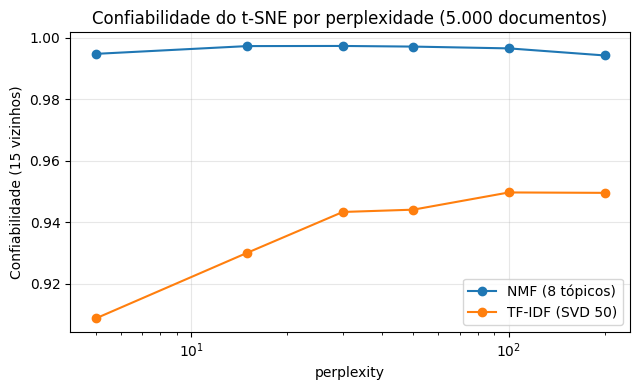

Perplexidade escolhida: {'nmf': 30, 'tfidf': 100}


In [11]:
rng = np.random.default_rng(SEMENTE)
indices_sub = np.sort(rng.choice(len(base), size=5000, replace=False))
perplexidades_c = [5, 15, 30, 50, 100, 200]
entradas = {'tfidf': Z_tfidf, 'nmf': X_nmf}

linhas = []
for nome, Z in entradas.items():
    Z_sub = Z[indices_sub]
    for p in perplexidades_c:
        emb_sub = TSNE(n_components=2, perplexity=p, init='pca', learning_rate='auto',
                       random_state=SEMENTE, n_jobs=-1).fit_transform(Z_sub)
        confiabilidade = trustworthiness(Z_sub, emb_sub, n_neighbors=15)
        linhas.append({'representacao': nome, 'perplexity': p, 'confiabilidade': float(confiabilidade)})
        print(f'{nome:6s} perplexity={p:3d}: confiabilidade = {confiabilidade:.4f}')

tabela_perp = pd.DataFrame(linhas)
tabela_perp.to_csv(pasta_q2 / 'confiabilidade_perplexidade.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(6.5, 4))
for nome, grupo in tabela_perp.groupby('representacao'):
    ax.plot(grupo['perplexity'], grupo['confiabilidade'], marker='o', label={'tfidf': 'TF-IDF (SVD 50)', 'nmf': 'NMF (8 tópicos)'}[nome])
ax.set_xscale('log')
ax.set_xlabel('perplexity')
ax.set_ylabel('Confiabilidade (15 vizinhos)')
ax.set_title('Confiabilidade do t-SNE por perplexidade (5.000 documentos)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(pasta_q2 / 'confiabilidade_perplexidade.png', dpi=160)
plt.show()

melhor_perp = {nome: int(g.loc[g['confiabilidade'].idxmax(), 'perplexity']) for nome, g in tabela_perp.groupby('representacao')}
print('Perplexidade escolhida:', melhor_perp)

Projeções finais, base completa:


  t-SNE nmf, perplexity=30: 39s, KL = 1.297


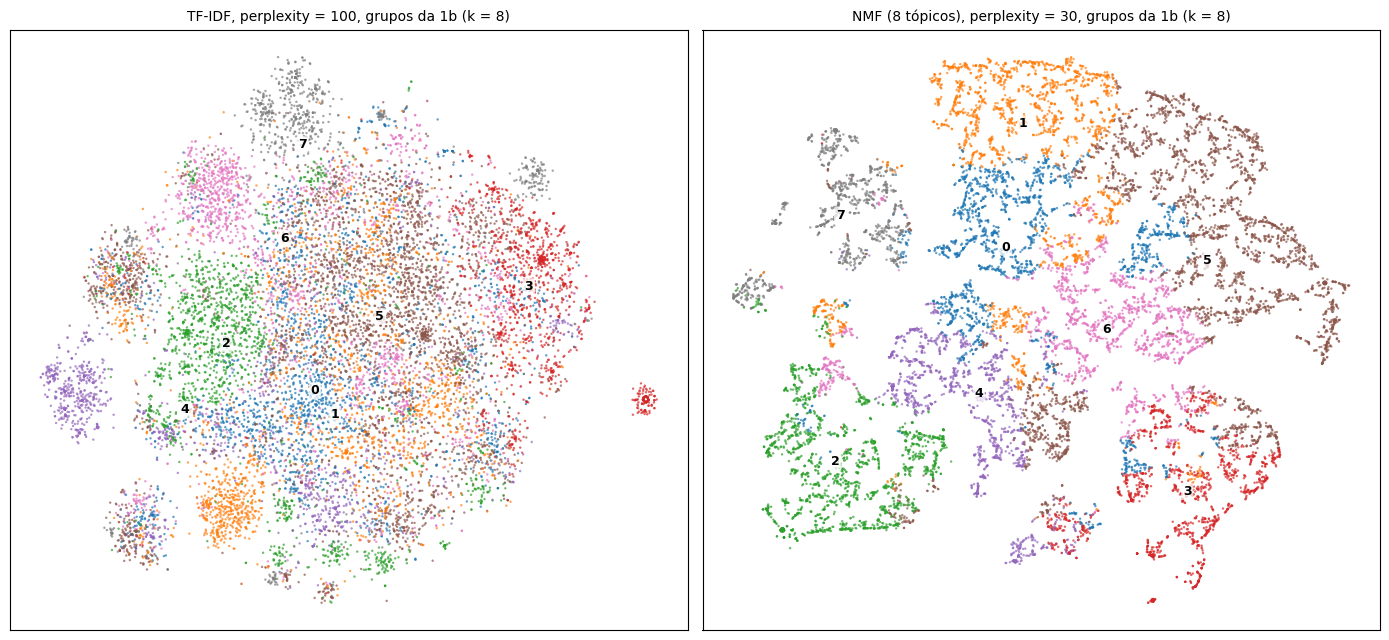

In [12]:
print('Projeções finais, base completa:')
emb_tfidf_final = projetar('tfidf', Z_tfidf, melhor_perp['tfidf'])
emb_nmf_final = projetar('nmf', X_nmf, melhor_perp['nmf'])

fig, eixos = plt.subplots(1, 2, figsize=(14, 6.5))
plotar_projecao(eixos[0], emb_tfidf_final, grupos_nmf,
                f'TF-IDF, perplexity = {melhor_perp["tfidf"]}, grupos da 1b (k = {k_nmf})')
plotar_projecao(eixos[1], emb_nmf_final, grupos_nmf,
                f'NMF (8 tópicos), perplexity = {melhor_perp["nmf"]}, grupos da 1b (k = {k_nmf})')
fig.tight_layout()
fig.savefig(pasta_q2 / 'melhores_projecoes.png', dpi=150)
plt.show()

pd.DataFrame({'indice_base': np.arange(len(base)),
              'tfidf_x': emb_tfidf_final[:, 0], 'tfidf_y': emb_tfidf_final[:, 1],
              'nmf_x': emb_nmf_final[:, 0], 'nmf_y': emb_nmf_final[:, 1]}
             ).to_csv(pasta_q2 / 'coordenadas_melhores_projecoes.csv', index=False)

**Resultado da 2c e análise.**

- **Perplexidade escolhida:** TF-IDF após SVD: **100**, com confiabilidade **0,9497**; NMF: **30**, com confiabilidade **0,9973**. Esses são os melhores valores entre os seis testados na subamostra fixa, não ótimos garantidos para qualquer base ou grade. A confiabilidade foi medida em relação ao SVD normalizado, no caso do TF-IDF, e aos oito tópicos normalizados, no caso do NMF; por isso não é uma comparação direta entre representações.
- **Cores comparáveis:** os dois painéis finais usam exatamente os grupos da **1b**, inclusive as mesmas cores e identificadores. Isso permite acompanhar os mesmos documentos e grupos nas duas projeções; as figuras dos itens a e b continuam usando os grupos da 1a.
- **Interpretação visual:** na projeção do TF-IDF, os grupos 0, 1 e 5 se misturam bastante na região central, enquanto partes dos grupos 2, 3, 4 e 7 são mais identificáveis. No NMF, as cores ocupam regiões mais contínuas, embora ainda haja fronteiras e pontos misturados. O agrupamento da 1b foi calculado no próprio espaço do NMF, de modo que esse maior alinhamento é esperado. A projeção do TF-IDF inclui variações lexicais que não se resumem aos oito tópicos. A disposição visual deve ser interpretada junto com as silhuetas e com as limitações do SVD e do t-SNE, sem tratar distâncias entre ilhas como medidas semânticas exatas.

# Questão 3 — Buscadores de palavras e documentos com word2vec

**Enunciado:** (a) escolher e aplicar um modelo word2vec pré-treinado compatível com o idioma; (b) com 5 palavras de consulta ausentes dos textos, encontrar para cada uma as 3 palavras mais parecidas do conjunto de textos e exibir os documentos onde aparecem; (c) implementar a busca de documentos pela média das 5 menores distâncias (DM5). Sempre com distância do cosseno, sem stemização e com remoção de stopwords.

**a) Modelo escolhido:** `word2vec-google-news-300`, o word2vec de 300 dimensões treinado pelo Google em cerca de 100 bilhões de palavras de notícias em **inglês**, idioma dos tweets. Ele tem 3 milhões de entradas; carregamos as **500 mil mais frequentes** (cerca de 600 MB em memória), o que cobre o vocabulário comum dos tweets e cabe em máquinas modestas. O arquivo (~1,6 GB) é baixado automaticamente para `modelos/` na primeira execução. Lemos o formato binário do word2vec diretamente com NumPy, sem depender do gensim.

**Normalização compatível com o modelo:** o vocabulário do Google News distingue maiúsculas de minúsculas, e o pré-processamento da Atividade 1 já converte tudo para minúsculas, então só entram as palavras cuja forma minúscula existe no modelo. Palavras sem vetor são descartadas, assim como as stopwords (lista em inglês do scikit-learn). Não há stemização. As palavras de consulta passam pela mesma normalização. Os vetores são normalizados para norma 1, de modo que a distância do cosseno é `1 − produto interno`.

In [13]:
import gzip
import urllib.request
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

URL_MODELO = 'https://github.com/RaRe-Technologies/gensim-data/releases/download/word2vec-google-news-300/word2vec-google-news-300.gz'
caminho_modelo = Path('modelos/word2vec-google-news-300.gz')
LIMITE_PALAVRAS = 500_000

if not caminho_modelo.is_file():
    caminho_modelo.parent.mkdir(exist_ok=True)
    print('Baixando o modelo (~1,6 GB)...')
    parcial = caminho_modelo.with_suffix('.gz.part')
    urllib.request.urlretrieve(URL_MODELO, parcial)
    parcial.replace(caminho_modelo)

def carregar_word2vec(caminho, limite):
    # Lê o formato binário do word2vec (cabeçalho "n d", depois palavra, espaço e d float32).
    with gzip.open(caminho, 'rb') as f:
        total, dimensao = map(int, f.readline().split())
        limite = min(limite, total)
        palavras = []
        vetores = np.empty((limite, dimensao), dtype=np.float32)
        for i in range(limite):
            caracteres = bytearray()
            while True:
                c = f.read(1)
                if not c:
                    raise EOFError('Modelo word2vec incompleto; baixe o arquivo novamente.')
                if c == b' ':
                    break
                if c != b'\n':
                    caracteres += c
            palavras.append(caracteres.decode('utf-8', errors='ignore'))
            dados_vetor = f.read(4 * dimensao)
            if len(dados_vetor) != 4 * dimensao:
                raise EOFError('Vetor incompleto no arquivo word2vec.')
            vetores[i] = np.frombuffer(dados_vetor, dtype='<f4')
    return palavras, vetores

t0 = time.perf_counter()
palavras_modelo, vetores_modelo = carregar_word2vec(caminho_modelo, LIMITE_PALAVRAS)
vetores_modelo /= np.maximum(np.linalg.norm(vetores_modelo, axis=1, keepdims=True), 1e-12)
indice_modelo = {p: i for i, p in enumerate(palavras_modelo)}
print(f'Modelo carregado: {len(palavras_modelo)} palavras x {vetores_modelo.shape[1]} dimensões em {time.perf_counter() - t0:.0f}s')

Modelo carregado: 500000 palavras x 300 dimensões em 8s


In [14]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

todos_tokens = set(t for tokens in base['tokens'] for t in tokens)

def normalizar_tokens(tokens):
    # Remove stopwords e palavras sem vetor no modelo; mantém as palavras distintas, na ordem de aparição.
    return list(dict.fromkeys(t for t in tokens if t not in STOPWORDS and t in indice_modelo))

base['palavras_q3'] = base['tokens'].map(normalizar_tokens)   # V(d)
com_vetor = base['palavras_q3'].map(len) > 0
print(f'Documentos com V(d) vazio (desconsiderados na busca): {int((~com_vetor).sum())}')

# Vocabulário da base que o modelo conhece, e matriz de vetores correspondente.
vocabulario_base = sorted(set(p for lista in base['palavras_q3'] for p in lista))
posicao_vocab = {p: i for i, p in enumerate(vocabulario_base)}
matriz_vocab = vetores_modelo[[indice_modelo[p] for p in vocabulario_base]]

tokens_sem_stop = {t for t in todos_tokens if t not in STOPWORDS}
print(f'Palavras distintas da base (sem stopwords): {len(tokens_sem_stop)}')
print(f'  com vetor no modelo: {len(vocabulario_base)} ({len(vocabulario_base) / len(tokens_sem_stop):.1%})')
print(f'  sem vetor (descartadas): {len(tokens_sem_stop) - len(vocabulario_base)}, por exemplo: {sorted(tokens_sem_stop - set(vocabulario_base))[:12]}')

Documentos com V(d) vazio (desconsiderados na busca): 84
Palavras distintas da base (sem stopwords): 13247
  com vetor no modelo: 7728 (58.3%)
  sem vetor (descartadas): 5519, por exemplo: ['aaaand', 'aaadvantage', 'aaalwayslate', 'aaba', 'aacom', 'aacustomerservice', 'aadavantage', 'aadelay', 'aadfw', 'aadv', 'aadvantage', 'aafail']


**b) Palavras de consulta e palavras mais parecidas.** As consultas são escolhidas de uma lista de candidatas ligadas ao tema da base (viagens aéreas) e só são aceitas se **não aparecerem em nenhum tweet** (nem como stopword) e tiverem vetor no modelo.

O notebook mostra exemplos e, ao final, tabelas expansíveis com **todos os documentos encontrados**, incluindo os textos completos. Essas tabelas também são exportadas para HTML e CSV.

In [15]:
candidatas = ['jetliner', 'hijacking', 'parachute', 'helicopter', 'aviator', 'airship', 'blimp']
consultas = []
for palavra in candidatas:
    if palavra in todos_tokens:
        print(f'  descartada (aparece nos textos): {palavra}')
    elif palavra not in indice_modelo:
        print(f'  descartada (sem vetor no modelo): {palavra}')
    elif len(consultas) < 5:
        consultas.append(palavra)
assert len(consultas) == 5 and not (set(consultas) & todos_tokens)
print('Palavras de consulta:', consultas)

def distancias_ao_vocabulario(palavra):
    return 1.0 - matriz_vocab @ vetores_modelo[indice_modelo[palavra]]

# Índice invertido: palavra -> documentos em que aparece.
documentos_da_palavra = {}
for indice_doc, lista in base['palavras_q3'].items():
    for p in lista:
        documentos_da_palavra.setdefault(p, []).append(indice_doc)

linhas_resumo, linhas_docs = [], []
for consulta in consultas:
    dist = distancias_ao_vocabulario(consulta)
    mais_proximas = np.argsort(dist, kind='stable')[:3]
    print(f'\n=== Consulta: {consulta!r} ===')
    for posicao in mais_proximas:
        palavra = vocabulario_base[posicao]
        docs = documentos_da_palavra[palavra]
        print(f'  {palavra!r}: distância do cosseno = {dist[posicao]:.4f}, aparece em {len(docs)} documento(s)')
        for d in docs[:3]:
            print(f'      [{d}] {base.loc[d, "text"]!r}')
        linhas_resumo.append({'consulta': consulta, 'palavra_parecida': palavra,
                              'distancia_cosseno': round(float(dist[posicao]), 4),
                              'n_documentos': len(docs),
                              'exemplos': ' || '.join(base.loc[d, 'text'] for d in docs[:3])})
        linhas_docs += [{'consulta': consulta, 'palavra_parecida': palavra, 'indice_base': d,
                         'tweet_id': base.loc[d, 'tweet_id'],
                         'texto': base.loc[d, 'text']} for d in docs]

pd.DataFrame(linhas_resumo).to_csv(pasta_q3 / 'palavras_parecidas.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(linhas_docs).to_csv(pasta_q3 / 'documentos_3b.csv', index=False, encoding='utf-8-sig')
print(f'\nLista completa de documentos por palavra: {len(linhas_docs)} linhas em documentos_3b.csv')

from IPython.display import HTML
from html import escape
documentos_3b = pd.DataFrame(linhas_docs)
paineis = []
for (consulta, palavra), tabela in documentos_3b.groupby(['consulta', 'palavra_parecida'], sort=False):
    titulo = f'{consulta} → {palavra}: {len(tabela)} documentos'
    paineis.append('<details><summary>' + escape(titulo) + '</summary>'
                   + tabela[['indice_base', 'tweet_id', 'texto']].to_html(index=False, escape=True)
                   + '</details>')
html_documentos = '\n'.join(paineis)
(pasta_q3 / 'documentos_3b.html').write_text(
    '<!doctype html><html lang="pt-BR"><meta charset="utf-8">'
    '<title>Questão 3b — documentos recuperados</title>'
    '<style>body{font:16px sans-serif;margin:2rem}table{border-collapse:collapse}'
    'td,th{padding:.4rem;border:1px solid #ccc}summary{cursor:pointer;margin:1rem 0}</style>'
    '<h1>Questão 3b — todos os documentos recuperados</h1>' + html_documentos + '</html>',
    encoding='utf-8')
display(HTML(html_documentos))

Palavras de consulta: ['jetliner', 'hijacking', 'parachute', 'helicopter', 'aviator']

=== Consulta: 'jetliner' ===
  'airliner': distância do cosseno = 0.1496, aparece em 1 documento(s)
      [5927] '@SouthwestAir your A-list program is a complete JOKE! Your company does not value loyal customers.Time to look for another "go-to" airliner'
  'plane': distância do cosseno = 0.2794, aparece em 584 documento(s)
      [74] "@VirginAmerica not worried, it's been a great ride in a new plane with great crew. All airlines should be like this."
      [97] '@VirginAmerica - Let 2 scanned in passengers leave the plane than told someone to remove their bag from 1st class bin? #uncomfortable'
      [115] '@VirginAmerica should I be concerned that I am about to fly on a plane that needs to be delayed due to a "tech stop"?'
  'airplane': distância do cosseno = 0.2934, aparece em 23 documento(s)
      [851] "@united system failure again = bad trend.  Software projects are like flying an airplane; ther

indice_base,tweet_id,texto
5927,568481017876623360,"@SouthwestAir your A-list program is a complete JOKE! Your company does not value loyal customers.Time to look for another ""go-to"" airliner"
indice_base,tweet_id,texto
74,569942903683813376,"@VirginAmerica not worried, it's been a great ride in a new plane with great crew. All airlines should be like this."
97,569907336485019648,@VirginAmerica - Let 2 scanned in passengers leave the plane than told someone to remove their bag from 1st class bin? #uncomfortable
115,569847920192655361,"@VirginAmerica should I be concerned that I am about to fly on a plane that needs to be delayed due to a ""tech stop""?"
188,569305113589714944,@VirginAmerica Having an issue finding a missing item on a plane. Can you help me find which airport my plane headed to next?
203,569260526976544768,@VirginAmerica cool picture of another VirginAmerica plane off our wing. What a site! http://t.co/5B2agFd8c4
283,568867068331864064,@VirginAmerica I think i left something on the plane yesterday. who do i call...ah!
367,568463892453724160,@VirginAmerica on VX399 from JFK to LA - dirty plane - not up to your standards.
368,568463244035289088,@VirginAmerica on flight VX399 headed to LA from JFK - dirtiest VA plane I have ever been on. Sad for a great airline.


**Análise (3b).** A busca por vizinhos de palavras funciona bem quando a consulta tem sinônimos próximos no vocabulário da base: `jetliner` retorna `airliner` (distância 0,15), `plane` e `airplane`; `helicopter` retorna `plane`, `aircraft` e `airplane`. Quando não há sinônimo, as palavras retornadas são apenas as mais próximas disponíveis, com distâncias altas e relação fraca com o sentido da consulta: `hijacking` retorna `hostage`, `terror` e `killing` (≈ 0,62), que nos tweets aparecem em sentido figurado ("held hostage", "killing me"); `parachute` retorna `plane`, `balloons` e `airplane`; e `aviator` retorna `sailor`, `pilots` e `pilot`. A palavra `plane` domina porque é frequente, aparece em 584 documentos e fica próxima de quase todo o tema de aviação. Na versão carregada (500 mil entradas), 41,7% das palavras distintas da base sem stopwords não têm vetor na forma normalizada. Entre elas há nomes de contas, hashtags e erros de digitação; a cobertura também depende do limite de vocabulário e da distinção entre maiúsculas e minúsculas. Não se deve atribuir essa ausência apenas ao domínio de notícias, nem estendê-la automaticamente ao modelo completo.

**c) Busca de documentos por DM5.** Para cada documento `d` com `V(d)` não vazio, `L5(d, w)` são as (até) cinco palavras de `V(d)` mais próximas de `w`; `DM5(d, w)` é a média das distâncias do cosseno entre `w` e essas palavras; os três documentos de menor `DM5` são recuperados. Em empates, prevalece o documento de menor índice. A função é testada antes com um exemplo pequeno, incluindo o caso de menos de cinco palavras.

In [16]:
def dm5_documento(dist_vocab, ids_palavras):
    # Média das (até) 5 menores distâncias à consulta entre as palavras do documento.
    distancias = np.sort(dist_vocab[ids_palavras])[:5]
    return float(distancias.mean()), distancias

# Testes: menos de 5 palavras usa todas; com mais de 5 usa só as 5 menores.
dist_teste = np.array([0.1, 0.9, 0.5, 0.3, 0.7, 0.2, 0.8])
assert abs(dm5_documento(dist_teste, [0, 1])[0] - 0.5) < 1e-12
assert abs(dm5_documento(dist_teste, [0, 1, 2, 3, 4, 5, 6])[0] - np.mean([0.1, 0.2, 0.3, 0.5, 0.7])) < 1e-12

ids_documentos = {i: np.array([posicao_vocab[p] for p in lista]) for i, lista in base['palavras_q3'].items() if lista}
print(f'Documentos considerados: {len(ids_documentos)} de {len(base)}')

linhas_3c = []
for consulta in consultas:
    dist = distancias_ao_vocabulario(consulta)
    indices = np.array(list(ids_documentos))
    dm5 = np.array([dm5_documento(dist, ids_documentos[i])[0] for i in indices])
    melhores = np.argsort(dm5, kind='stable')[:3]
    print(f'\n=== Consulta: {consulta!r} ===')
    for ordem, pos in enumerate(melhores, start=1):
        d = int(indices[pos])
        _, distancias = dm5_documento(dist, ids_documentos[d])
        palavras_l5 = [vocabulario_base[j] for j in ids_documentos[d][np.argsort(dist[ids_documentos[d]], kind='stable')[:5]]]
        print(f'  {ordem}. [{d}] DM5 = {dm5[pos]:.4f} | L5 = {palavras_l5}\n     {base.loc[d, "text"]!r}')
        linhas_3c.append({'consulta': consulta, 'posicao': ordem, 'indice_base': d, 'tweet_id': base.loc[d, 'tweet_id'],
                          'dm5': round(float(dm5[pos]), 4), 'palavras_l5': ', '.join(palavras_l5),
                          'texto': base.loc[d, 'text']})

pd.DataFrame(linhas_3c).to_csv(pasta_q3 / 'documentos_3c.csv', index=False, encoding='utf-8-sig')

Documentos considerados: 14556 de 14640

=== Consulta: 'jetliner' ===
  1. [7471] DM5 = 0.3652 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  2. [7172] DM5 = 0.4231 | L5 = ['plane', 'airplane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  3. [129] DM5 = 0.4510 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'



=== Consulta: 'hijacking' ===
  1. [9834] DM5 = 0.7183 | L5 = ['hostage', 'passengers', 'crash', 'plane', 'computer']
     '@USAirways holding your passengers hostage during your computer crash is not customer friendly, let us off the plane or get us moving'
  2. [129] DM5 = 0.7478 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'
  3. [5854] DM5 = 0.7478 | L5 = ['flight']
     '@SouthwestAir flight # 317'

=== Consulta: 'parachute' ===
  1. [7172] DM5 = 0.5954 | L5 = ['plane', 'airplane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  2. [7471] DM5 = 0.5977 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  3. [129] DM5 = 0.6512 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'



=== Consulta: 'helicopter' ===
  1. [7172] DM5 = 0.4851 | L5 = ['plane', 'airplane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  2. [7471] DM5 = 0.4937 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  3. [4410] DM5 = 0.5973 | L5 = ['plane', 'freezing']
     '@SouthwestAir freezing in the plane'

=== Consulta: 'aviator' ===
  1. [7172] DM5 = 0.6071 | L5 = ['airplane', 'plane', 'flying']
     '@JetBlue what else on this plane is duct-taped?? #ohboy #shouldigetoutandpush #airplane #flying… http://t.co/R9ZsVzuRLw'
  2. [7471] DM5 = 0.6268 | L5 = ['plane', 'flight']
     '@JetBlue the whole plane. Flight 561 from LGA to PBI http://t.co/4Ktk2hsmGy'
  3. [129] DM5 = 0.6299 | L5 = ['flight']
     '@VirginAmerica is flight 882 Cancelled Flightled and what do I do if it is?'


**Análise (3c).** O DM5 recupera documentos cujas palavras estão próximas da consulta, mas tem um viés de tamanho: se `V(d)` tem menos de cinco palavras, a média usa todas, então um tweet curto com uma única palavra próxima obtém DM5 baixo. É o caso do documento 129 (`flight`, DM5 = 0,451 para `jetliner`), que aparece entre os três primeiros para quatro das cinco consultas, ao lado dos documentos 7172 e 7471, que contêm `plane` e `airplane`. Para `hijacking`, o primeiro resultado (documento 9834: "holding your passengers hostage during your computer crash...") é o mais coerente com a consulta, pois reúne `hostage`, `passengers` e `crash`; os dois seguintes empatam em DM5 com uma única palavra genérica (`flight`), o que mostra a fraqueza do método para consultas sem sinônimos na base. Em relação à 3b, que lista **todos** os documentos que contêm as palavras parecidas, o DM5 faz uma classificação dos documentos por proximidade média e retorna só três, o que é mais útil para consultas, mas favorece documentos curtos e genéricos.

# Questão 4 — Classificação com redes neurais (Embedding + LSTM e Embedding + Conv1D)

**Enunciado:** resolver novamente o problema de classificação de textos da lista anterior e comparar com os resultados obtidos lá, usando (a) uma rede neural com camadas de Embedding e LSTM e (b) uma rede neural com camadas de Embedding e convolucionais 1D.

**Problema e protocolo (os mesmos da lista 2):** rótulo `airline_sentiment` (negativo, neutro e positivo), textos com o pré-processamento da lista 1, divisão estratificada de 70% para treino e 30% para teste com `random_state=42` e validação cruzada estratificada de 5 partições (`shuffle=True`, `random_state=42`). As duas divisões dependem só dos rótulos e do número de documentos, então os conjuntos de teste e as partições são exatamente os da lista 2. Para que a comparação fique toda neste notebook, os três classificadores da lista 2 (Regressão Logística, Naive Bayes multinomial e SVM linear, sobre CountVectorizer e TF-IDF) são retreinados abaixo, e suas métricas são conferidas contra as salvas na Atividade 2.

**Redes (PyTorch):**

- **Vocabulário:** palavras com pelo menos 2 ocorrências nos textos de treino; as demais viram `<unk>`. Cada tweet vira a sequência dos índices de suas palavras (no máximo 33, o tamanho do maior tweet), completada com `<pad>` até o maior tweet do lote.
- **Embedding:** 100 dimensões, treinado do zero junto com a rede.
- **a) LSTM:** LSTM bidirecional com 64 unidades por direção. As sequências são empacotadas (`pack_padded_sequence`), para que o LSTM não processe o preenchimento, e a classificação usa os estados finais das duas direções (128 valores).
- **b) Conv1D:** três convoluções 1D em paralelo, com janelas de 3, 4 e 5 palavras e 64 filtros cada (ReLU), seguidas de max pooling global sobre a sequência, sem considerar as posições de preenchimento (arquitetura de Kim, 2014). A saída tem 192 valores.
- **Saída e treino:** dropout de 0,5 e camada linear com 3 saídas; entropia cruzada sem pesos de classe (os classificadores da lista 2 também não usaram), otimizador Adam com taxa 10⁻³ e lotes de 64.
- **Parada antecipada:** 15% do treino (estratificado) fica separado como validação. O treino vai até 20 épocas, para quando a perda de validação não melhora por 3 épocas e restaura os pesos da melhor época. O conjunto de teste não participa do treino nem da escolha da época.

Os hiperparâmetros foram fixados antes dos experimentos, com valores usuais para textos curtos, e não foram ajustados no conjunto de teste.

In [17]:
import copy
import time
from collections import Counter
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

pasta_q4 = pasta_resultados / 'questao_4'
pasta_q4.mkdir(parents=True, exist_ok=True)

classes = np.array(['negative', 'neutral', 'positive'])
rotulos_q4 = base['airline_sentiment'].to_numpy()
y_q4 = np.searchsorted(classes, rotulos_q4)

# Mesma divisão 70/30 e mesmas 5 partições da lista 2.
idx_treino, idx_teste = train_test_split(np.arange(len(base)), test_size=0.3,
                                         random_state=42, stratify=rotulos_q4)
particoes = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
                 .split(np.zeros(len(base)), rotulos_q4))
print(f'Treino: {len(idx_treino)} | teste: {len(idx_teste)}')
print('Classes no teste:', dict(zip(classes, np.bincount(y_q4[idx_teste]))))

def calcular_metricas(y_real, y_pred):
    p_mi, r_mi, f_mi, _ = precision_recall_fscore_support(y_real, y_pred, average='micro', zero_division=0)
    p_ma, r_ma, f_ma, _ = precision_recall_fscore_support(y_real, y_pred, average='macro', zero_division=0)
    f1_classes = precision_recall_fscore_support(y_real, y_pred, labels=[0, 1, 2], average=None, zero_division=0)[2]
    return {'acuracia': accuracy_score(y_real, y_pred),
            'precisao_micro': p_mi, 'recall_micro': r_mi, 'f1_micro': f_mi,
            'precisao_macro': p_ma, 'recall_macro': r_ma, 'f1_macro': f_ma,
            **{f'f1_{c}': f for c, f in zip(classes, f1_classes)}}

Treino: 10248 | teste: 4392
Classes no teste: {np.str_('negative'): np.int64(2753), np.str_('neutral'): np.int64(930), np.str_('positive'): np.int64(709)}


**Classificadores da lista 2 (referência).** Os vetorizadores são ajustados sobre a base inteira, como na Atividade 2, e cada classificador é treinado na divisão 70/30 e nas 5 partições.

**Limitação metodológica da referência:** ajustar o vocabulário e o IDF na base inteira permite que a representação incorpore informação dos textos de teste. Mantemos esse procedimento apenas para reproduzir a lista 2, identificando-o explicitamente; ele não constitui uma comparação inteiramente livre de vazamento. As redes montam o vocabulário apenas no subconjunto de ajuste. Em uma comparação com isolamento completo, os vetorizadores devem ser ajustados dentro de cada partição de treino, usando um `Pipeline`.

In [18]:
representacoes_l2 = {
    'count': CountVectorizer().fit_transform(base['texto_processado']),
    'tfidf': TfidfVectorizer().fit_transform(base['texto_processado']),
}
classificadores_l2 = {'logreg': LogisticRegression(max_iter=1000), 'nb': MultinomialNB(), 'svm': LinearSVC()}

resultados_teste, resultados_cv, predicoes_teste = [], [], {}
t0 = time.perf_counter()
for nome_rep, X in representacoes_l2.items():
    for nome_clf, clf in classificadores_l2.items():
        modelo = f'{nome_rep} + {nome_clf}'
        y_pred = clone(clf).fit(X[idx_treino], y_q4[idx_treino]).predict(X[idx_teste])
        predicoes_teste[modelo] = y_pred
        resultados_teste.append({'modelo': modelo, **calcular_metricas(y_q4[idx_teste], y_pred)})
        for fold, (tr, te) in enumerate(particoes):
            y_fold = clone(clf).fit(X[tr], y_q4[tr]).predict(X[te])
            resultados_cv.append({'modelo': modelo, 'fold': fold, **calcular_metricas(y_q4[te], y_fold)})
print(f'Classificadores da lista 2 retreinados em {time.perf_counter() - t0:.0f}s')

# Conferência contra os resultados salvos na Atividade 2, quando disponíveis.
caminho_l2 = Path('../atividade_2/resultados/questao_2/metricas_resumo.csv')
if caminho_l2.is_file():
    salvas = pd.read_csv(caminho_l2)
    salvas['modelo'] = salvas['representacao'] + ' + ' + salvas['classificador']
    conferencia = pd.DataFrame(resultados_teste)[['modelo', 'acuracia', 'f1_macro']].merge(
        salvas[['modelo', 'acuracia', 'f1_macro']], on='modelo', suffixes=('_agora', '_lista2'))
    display(conferencia.round(4))
    diferenca = (conferencia[['acuracia_agora', 'f1_macro_agora']].to_numpy()
                 - conferencia[['acuracia_lista2', 'f1_macro_lista2']].to_numpy())
    print(f'Maior diferença absoluta em relação à lista 2: {np.abs(diferenca).max():.4f}')

Classificadores da lista 2 retreinados em 9s


,modelo,acuracia_agora,f1_macro_agora,acuracia_lista2,f1_macro_lista2
0,count + logreg,0.8010,0.7417,0.8010,0.7417
1,count + nb,0.7723,0.6739,0.7723,0.6739
2,count + svm,0.7771,0.7185,0.7771,0.7185
3,tfidf + logreg,0.7978,0.7202,0.7978,0.7202
4,tfidf + nb,0.6683,0.4006,0.6683,0.4006
5,tfidf + svm,0.7996,0.7373,0.7996,0.7373


Maior diferença absoluta em relação à lista 2: 0.0000


**Redes neurais.** Funções de vocabulário, codificação, as duas arquiteturas e o laço de treino com parada antecipada.

In [19]:
COMPRIMENTO_MAX = int(base['tokens'].map(len).max())
torch.set_num_threads(min(4, os.cpu_count() or 1))

def montar_vocabulario(lista_tokens, freq_minima=2):
    contagem = Counter(t for tokens in lista_tokens for t in tokens)
    palavras = ['<pad>', '<unk>'] + sorted(t for t, c in contagem.items() if c >= freq_minima)
    return {p: i for i, p in enumerate(palavras)}

def codificar(lista_tokens, vocab):
    # Matriz de índices (documentos x COMPRIMENTO_MAX), com 0 = <pad> e 1 = <unk>, e o tamanho de cada sequência.
    X = torch.zeros((len(lista_tokens), COMPRIMENTO_MAX), dtype=torch.long)
    comprimentos = torch.zeros(len(lista_tokens), dtype=torch.long)
    for i, tokens in enumerate(lista_tokens):
        ids = [vocab.get(t, 1) for t in tokens][:COMPRIMENTO_MAX]
        X[i, :len(ids)] = torch.tensor(ids)
        comprimentos[i] = len(ids)
    return X, comprimentos

class RedeLSTM(nn.Module):
    def __init__(self, n_vocab, dim_embedding=100, n_unidades=64, n_classes=3, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(n_vocab, dim_embedding, padding_idx=0)
        self.lstm = nn.LSTM(dim_embedding, n_unidades, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.saida = nn.Linear(2 * n_unidades, n_classes)

    def forward(self, x, comprimentos):
        pacote = pack_padded_sequence(self.embedding(x), comprimentos, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(pacote)
        h = torch.cat([h[-2], h[-1]], dim=1)  # estado final das direções direta e reversa
        return self.saida(self.dropout(h))

class RedeConv1D(nn.Module):
    def __init__(self, n_vocab, dim_embedding=100, n_filtros=64, janelas=(3, 4, 5), n_classes=3, dropout=0.5):
        super().__init__()
        self.janelas = janelas
        self.embedding = nn.Embedding(n_vocab, dim_embedding, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(dim_embedding, n_filtros, j) for j in janelas)
        self.dropout = nn.Dropout(dropout)
        self.saida = nn.Linear(n_filtros * len(janelas), n_classes)

    def forward(self, x, comprimentos):
        if x.size(1) < max(self.janelas):  # garante ao menos uma janela por sequência
            x = nn.functional.pad(x, (0, max(self.janelas) - x.size(1)))
        emb = self.embedding(x).transpose(1, 2)  # (lote, dimensão, tempo)
        maximos = []
        for conv, j in zip(self.convs, self.janelas):
            ativacao = torch.relu(conv(emb))  # (lote, filtros, tempo - j + 1)
            # Só aceita janelas inteiramente no tweet; para tweets menores que j, aceita a primeira janela com padding.
            posicoes = torch.arange(ativacao.size(2))
            validas = posicoes[None, :] < torch.clamp(comprimentos - j + 1, min=1)[:, None]
            maximos.append(ativacao.masked_fill(~validas[:, None, :], float('-inf')).max(dim=2).values)
        return self.saida(self.dropout(torch.cat(maximos, dim=1)))

ARQUITETURAS = {'lstm': RedeLSTM, 'conv1d': RedeConv1D}

def prever_logits(rede, X, comprimentos, tamanho_lote=512):
    rede.eval()
    saidas = []
    with torch.no_grad():
        for ini in range(0, len(X), tamanho_lote):
            c = comprimentos[ini:ini + tamanho_lote]
            saidas.append(rede(X[ini:ini + tamanho_lote, :int(c.max())], c))
    return torch.cat(saidas)

def treinar_rede(arquitetura, idx_tr, semente=SEMENTE, max_epocas=20, paciencia=3, tamanho_lote=64):
    # Separa 15% do treino para validação, monta o vocabulário só com o restante e treina com parada antecipada.
    torch.manual_seed(semente)
    gerador = torch.Generator().manual_seed(semente)
    idx_ajuste, idx_val = train_test_split(idx_tr, test_size=0.15, random_state=semente, stratify=y_q4[idx_tr])
    vocab = montar_vocabulario(base['tokens'].iloc[idx_ajuste])
    X_aj, c_aj = codificar(base['tokens'].iloc[idx_ajuste].tolist(), vocab)
    X_val, c_val = codificar(base['tokens'].iloc[idx_val].tolist(), vocab)
    y_aj, y_val = torch.tensor(y_q4[idx_ajuste]), torch.tensor(y_q4[idx_val])

    rede = ARQUITETURAS[arquitetura](len(vocab))
    otimizador = torch.optim.Adam(rede.parameters(), lr=1e-3)
    perda_fn = nn.CrossEntropyLoss()
    historico, melhor_perda, melhor_estado, sem_melhora = [], np.inf, None, 0
    for epoca in range(1, max_epocas + 1):
        rede.train()
        ordem = torch.randperm(len(X_aj), generator=gerador)
        soma_perda = 0.0
        for ini in range(0, len(ordem), tamanho_lote):
            lote = ordem[ini:ini + tamanho_lote]
            c = c_aj[lote]
            otimizador.zero_grad()
            perda = perda_fn(rede(X_aj[lote, :int(c.max())], c), y_aj[lote])
            perda.backward()
            otimizador.step()
            soma_perda += perda.item() * len(lote)
        logits_val = prever_logits(rede, X_val, c_val)
        perda_val = perda_fn(logits_val, y_val).item()
        historico.append({'epoca': epoca, 'perda_treino': soma_perda / len(X_aj), 'perda_validacao': perda_val,
                          'acuracia_validacao': (logits_val.argmax(1) == y_val).float().mean().item()})
        if perda_val < melhor_perda:
            melhor_perda, melhor_estado, sem_melhora = perda_val, copy.deepcopy(rede.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                break
    rede.load_state_dict(melhor_estado)
    melhor_epoca = int(np.argmin([h['perda_validacao'] for h in historico])) + 1
    return rede, vocab, pd.DataFrame(historico), melhor_epoca

def avaliar_rede(rede, vocab, idx):
    X, c = codificar(base['tokens'].iloc[idx].tolist(), vocab)
    return prever_logits(rede, X, c).argmax(1).numpy()

# Teste rápido das formas de saída, incluindo um tweet de uma palavra (menor que a janela de 5 da Conv1D).
x_teste = torch.tensor([[5, 6, 7, 0, 0], [8, 0, 0, 0, 0]])
for nome, Classe in ARQUITETURAS.items():
    assert Classe(20).eval()(x_teste, torch.tensor([3, 1])).shape == (2, 3), nome
print(f'Comprimento máximo das sequências: {COMPRIMENTO_MAX} tokens')

Comprimento máximo das sequências: 33 tokens


**a) e b) Treino na divisão 70/30 e avaliação no conjunto de teste.**

Embedding + LSTM: vocabulário de 4433 palavras, 528,679 parâmetros, 6 épocas (melhor: 3), 20s
RedeLSTM(
  (embedding): Embedding(4433, 100, padding_idx=0)
  (lstm): LSTM(100, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (saida): Linear(in_features=128, out_features=3, bias=True)
)


Embedding + Conv1D: vocabulário de 4433 palavras, 520,871 parâmetros, 9 épocas (melhor: 6), 10s
RedeConv1D(
  (embedding): Embedding(4433, 100, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(100, 64, kernel_size=(3,), stride=(1,))
    (1): Conv1d(100, 64, kernel_size=(4,), stride=(1,))
    (2): Conv1d(100, 64, kernel_size=(5,), stride=(1,))
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (saida): Linear(in_features=192, out_features=3, bias=True)
)


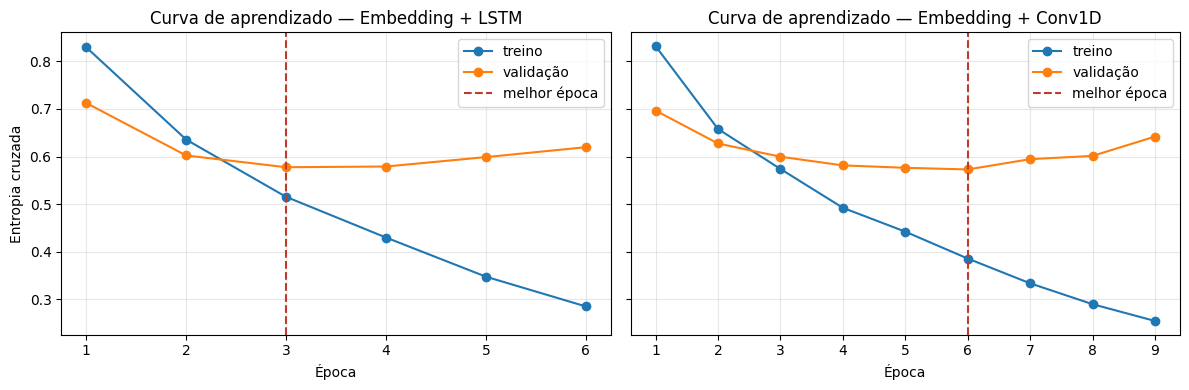

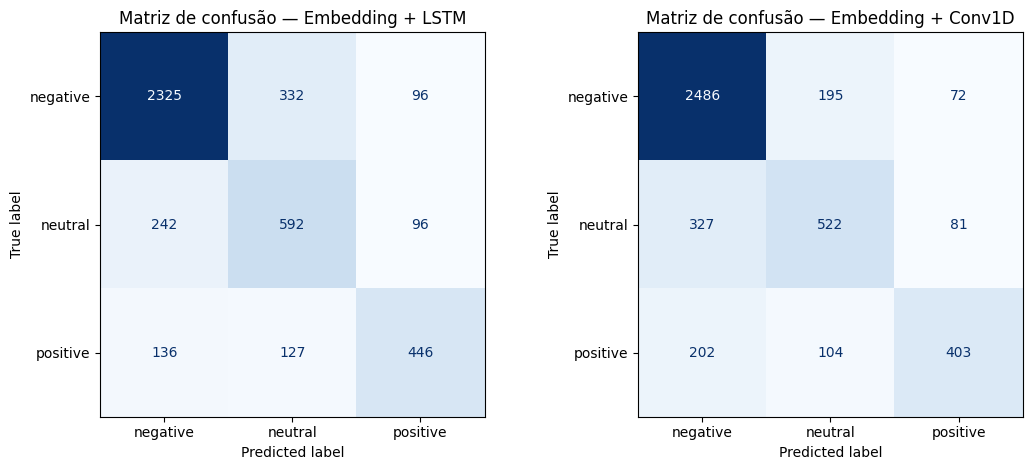

In [20]:
redes, historicos = {}, {}
nomes_redes = {'lstm': 'Embedding + LSTM', 'conv1d': 'Embedding + Conv1D'}
for arquitetura, nome in nomes_redes.items():
    t0 = time.perf_counter()
    rede, vocab, historico, melhor_epoca = treinar_rede(arquitetura, idx_treino)
    duracao = time.perf_counter() - t0
    y_pred = avaliar_rede(rede, vocab, idx_teste)
    redes[arquitetura], historicos[arquitetura] = (rede, vocab), historico
    predicoes_teste[nome] = y_pred
    resultados_teste.append({'modelo': nome, **calcular_metricas(y_q4[idx_teste], y_pred)})
    historico.to_csv(pasta_q4 / f'historico_{arquitetura}.csv', index=False)
    n_parametros = sum(p.numel() for p in rede.parameters())
    print(f'{nome}: vocabulário de {len(vocab)} palavras, {n_parametros:,} parâmetros, '
          f'{len(historico)} épocas (melhor: {melhor_epoca}), {duracao:.0f}s')
    print(rede)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (arquitetura, nome) in zip(eixos, nomes_redes.items()):
    h = historicos[arquitetura]
    ax.plot(h['epoca'], h['perda_treino'], marker='o', label='treino')
    ax.plot(h['epoca'], h['perda_validacao'], marker='o', label='validação')
    ax.axvline(h.loc[h['perda_validacao'].idxmin(), 'epoca'], color='#C0392B', linestyle='--', label='melhor época')
    ax.set_title(f'Curva de aprendizado — {nome}')
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
    ax.legend()
eixos[0].set_ylabel('Entropia cruzada')
fig.tight_layout()
fig.savefig(pasta_q4 / 'curvas_aprendizado.png', dpi=160)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (arquitetura, nome) in zip(eixos, nomes_redes.items()):
    matriz = confusion_matrix(y_q4[idx_teste], predicoes_teste[nome], labels=[0, 1, 2])
    pd.DataFrame(matriz, index=classes, columns=classes).to_csv(
        pasta_q4 / f'matriz_confusao_{arquitetura}.csv', index_label='classe_real')
    ConfusionMatrixDisplay(matriz, display_labels=classes).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Matriz de confusão — {nome}')
fig.tight_layout()
fig.savefig(pasta_q4 / 'matrizes_confusao.png', dpi=160)
plt.show()

**Validação cruzada (5 partições).** Cada rede é treinada do zero em cada partição, com o mesmo procedimento (vocabulário, validação interna de 15% e parada antecipada).

In [21]:
t0 = time.perf_counter()
for arquitetura, nome in nomes_redes.items():
    for fold, (tr, te) in enumerate(particoes):
        rede, vocab, historico, melhor_epoca = treinar_rede(arquitetura, tr)
        resultados_cv.append({'modelo': nome, 'fold': fold, 'epocas': melhor_epoca,
                              **calcular_metricas(y_q4[te], avaliar_rede(rede, vocab, te))})
        print(f'  {nome}, partição {fold}: melhor época {melhor_epoca}, F1 macro = {resultados_cv[-1]["f1_macro"]:.4f}')
print(f'Validação cruzada das redes em {time.perf_counter() - t0:.0f}s')

  Embedding + LSTM, partição 0: melhor época 3, F1 macro = 0.6909


  Embedding + LSTM, partição 1: melhor época 3, F1 macro = 0.7059


  Embedding + LSTM, partição 2: melhor época 3, F1 macro = 0.7026


  Embedding + LSTM, partição 3: melhor época 4, F1 macro = 0.6977


  Embedding + LSTM, partição 4: melhor época 4, F1 macro = 0.7142


  Embedding + Conv1D, partição 0: melhor época 4, F1 macro = 0.6930


  Embedding + Conv1D, partição 1: melhor época 7, F1 macro = 0.7095


  Embedding + Conv1D, partição 2: melhor época 6, F1 macro = 0.7047


  Embedding + Conv1D, partição 3: melhor época 6, F1 macro = 0.6987


  Embedding + Conv1D, partição 4: melhor época 5, F1 macro = 0.7007
Validação cruzada das redes em 163s


**Comparação com a lista 2.**

Conjunto de teste (30%) e validação cruzada (média e desvio das 5 partições), ordenado pelo F1 macro no teste:


,modelo,tipo,acuracia,precisao_macro,recall_macro,f1_macro,f1_micro,f1_negative,f1_neutral,f1_positive,cv_acuracia_media,cv_f1_macro_media,cv_f1_macro_desvio
0,count + logreg,lista 2,0.8010,0.7524,0.7327,0.7417,0.8010,0.8786,0.6243,0.7223,0.7997,0.7396,0.0086
1,tfidf + svm,lista 2,0.7996,0.7589,0.7204,0.7373,0.7996,0.8762,0.6100,0.7257,0.8024,0.7381,0.0061
2,tfidf + logreg,lista 2,0.7978,0.7744,0.6877,0.7202,0.7978,0.8771,0.6064,0.6772,0.8037,0.7291,0.0074
3,count + svm,lista 2,0.7771,0.7221,0.7160,0.7185,0.7771,0.8596,0.5951,0.7008,0.7801,0.7204,0.0070
4,Embedding + LSTM,rede neural,0.7657,0.7075,0.7034,0.7041,0.7657,0.8523,0.5977,0.6622,0.7736,0.7022,0.0087
5,Embedding + Conv1D,rede neural,0.7766,0.7284,0.6776,0.6985,0.7766,0.8620,0.5962,0.6372,0.7814,0.7013,0.0062
6,count + nb,lista 2,0.7723,0.7550,0.6360,0.6739,0.7723,0.8597,0.5281,0.6339,0.7723,0.6768,0.0105
7,tfidf + nb,lista 2,0.6683,0.7961,0.4098,0.4006,0.6683,0.7934,0.1894,0.2192,0.6716,0.4118,0.0167


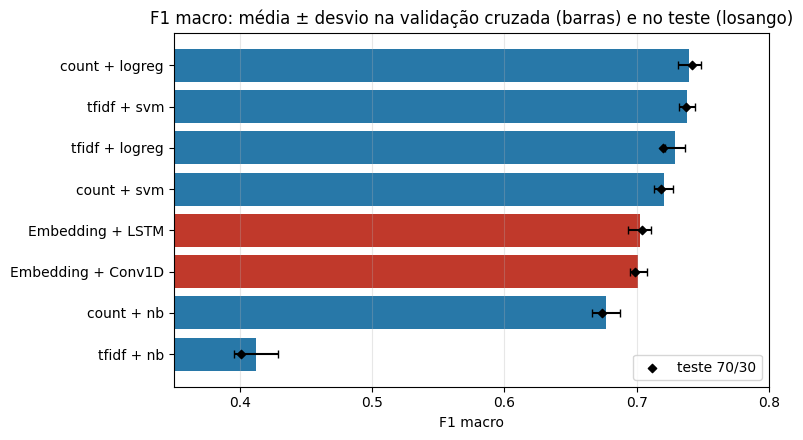

In [22]:
cv_q4 = pd.DataFrame(resultados_cv)
cv_q4.to_csv(pasta_q4 / 'validacao_cruzada.csv', index=False, encoding='utf-8-sig')
resumo_cv = cv_q4.groupby('modelo', sort=False).agg(
    cv_acuracia_media=('acuracia', 'mean'), cv_acuracia_desvio=('acuracia', 'std'),
    cv_f1_macro_media=('f1_macro', 'mean'), cv_f1_macro_desvio=('f1_macro', 'std'),
    cv_f1_micro_media=('f1_micro', 'mean'), cv_f1_micro_desvio=('f1_micro', 'std'),
).reset_index()

comparacao_q4 = pd.DataFrame(resultados_teste).merge(resumo_cv, on='modelo')
comparacao_q4.insert(1, 'tipo', np.where(comparacao_q4['modelo'].isin(nomes_redes.values()), 'rede neural', 'lista 2'))
comparacao_q4.to_csv(pasta_q4 / 'comparacao_modelos.csv', index=False, encoding='utf-8-sig')

colunas = ['modelo', 'tipo', 'acuracia', 'precisao_macro', 'recall_macro', 'f1_macro', 'f1_micro',
           'f1_negative', 'f1_neutral', 'f1_positive', 'cv_acuracia_media', 'cv_f1_macro_media', 'cv_f1_macro_desvio']
print('Conjunto de teste (30%) e validação cruzada (média e desvio das 5 partições), ordenado pelo F1 macro no teste:')
display(comparacao_q4[colunas].sort_values('f1_macro', ascending=False).round(4).reset_index(drop=True))

ordem = comparacao_q4.sort_values('cv_f1_macro_media')
cores = np.where(ordem['tipo'] == 'rede neural', '#C0392B', '#2878A8')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(ordem['modelo'], ordem['cv_f1_macro_media'], xerr=ordem['cv_f1_macro_desvio'], color=cores, capsize=3)
ax.scatter(ordem['f1_macro'], ordem['modelo'], color='black', marker='D', s=18, zorder=3, label='teste 70/30')
ax.set_xlabel('F1 macro')
ax.set_title('F1 macro: média ± desvio na validação cruzada (barras) e no teste (losango)')
ax.set_xlim(0.35, 0.8)
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(pasta_q4 / 'comparacao_f1_macro.png', dpi=160)
plt.show()

predicoes_q4 = pd.DataFrame({'indice_base': idx_teste,
                             'tweet_id': base.iloc[idx_teste]['tweet_id'].to_numpy(),
                             'classe_real': classes[y_q4[idx_teste]]})
for nome, y_pred in predicoes_teste.items():
    predicoes_q4[nome] = classes[y_pred]
predicoes_q4.to_csv(pasta_q4 / 'predicoes_teste.csv', index=False, encoding='utf-8-sig')

**Análise da Questão 4.**

- **Embedding + LSTM:** acurácia de 76,57%, F1 macro de 0,7041 no teste e 0,7022 ± 0,0087 na validação cruzada. F1 por classe: negativo 0,8523, neutro 0,5977, positivo 0,6622.
- **Embedding + Conv1D:** acurácia de 77,66%, F1 macro de 0,6985 no teste e 0,7013 ± 0,0062 na validação cruzada. F1 por classe: negativo 0,8620, neutro 0,5962, positivo 0,6372.

O maior F1 macro no teste foi o de **count + logreg (0,7417)**. As redes não superaram essa referência nesta execução. Em validação cruzada, a diferença entre as médias de F1 macro de LSTM e Conv1D foi de **0,0009**, pequena diante da variação observada entre partições; isso não demonstra superioridade consistente de uma arquitetura sobre a outra.

O F1 da classe negativa é maior que o da classe neutra nas duas redes. A acurácia e o F1 micro são influenciados pela classe majoritária, enquanto o F1 macro dá peso igual às três classes e evidencia essa dificuldade. Nas matrizes de confusão, 242 tweets neutros foram classificados como negativos pela LSTM e 327 pela Conv1D. A Conv1D acerta mais exemplos negativos, mas isso não se traduz no melhor F1 macro entre as duas redes.

As menores perdas de validação ocorreram nas épocas **3 (LSTM)** e **6 (Conv1D)**. Depois desses pontos, a perda de treino continuou caindo enquanto a de validação aumentou, um sinal de sobreajuste. A parada antecipada restaura esses pesos para a avaliação, em vez de usar os da última época.

Os embeddings foram aprendidos do zero nesta base, sem transferir os vetores usados na questão 3. Os modelos lineares podem se beneficiar de palavras diretamente discriminativas em textos curtos. A comparação também tem uma limitação: os vetorizadores clássicos foram ajustados na base inteira para reproduzir a lista 2, enquanto o vocabulário das redes usa apenas o subconjunto de ajuste. Portanto, estes resultados reproduzem o protocolo anterior, mas não isolam apenas o efeito da arquitetura.

# Questão 5 — spaCy: classes gramaticais, entidades nomeadas e grafo de coocorrência

**Enunciado:** usando a base de textos e a spaCy, (a) extrair as etiquetas gramaticais (POS) de cada token; (b) calcular e plotar as frequências de cada classe gramatical; (c) escolher um tipo de entidade nomeada pré-treinada, de preferência um tipo com boa chance de aparecer mais de uma vez em cada documento, e reconhecer essas entidades; (d) gerar um grafo com pesos em que os nós são as entidades e as arestas ligam pares de entidades que aparecem juntas em um mesmo documento, com peso igual ao número dessas ocorrências, e plotá-lo com NetworkX, com espessura das arestas proporcional ao peso.

**Modelo:** `en_core_web_lg`, pipeline pré-treinado da spaCy para inglês, com etiquetas POS universais (`token.pos_`), etiquetas detalhadas (`token.tag_`) e reconhecimento de entidades nomeadas.

**Texto de entrada:** os itens a–d usam `texto_processado`, exatamente a base após o pré-processamento da lista 1, conforme a orientação geral do enunciado. Minúsculas e remoção de pontuação alteram pistas utilizadas pelo modelo; os erros de reconhecimento precisam ser considerados ao interpretar os resultados. Como análise complementar, comparamos as contagens de entidades dessa versão com as do texto original (apenas com entidades HTML decodificadas), na mesma amostra fixa de 2.000 tweets. Contar entidades não mede acurácia: sem anotações de referência não podemos afirmar qual versão é mais correta.

In [23]:
import html
import importlib
import itertools
import networkx as nx
import spacy

pasta_q5 = pasta_resultados / 'questao_5'
pasta_q5.mkdir(parents=True, exist_ok=True)

MODELO_SPACY = 'en_core_web_lg'
try:
    nlp = spacy.load(MODELO_SPACY)
except OSError:
    # No Colab, baixa o modelo na primeira execução.
    spacy.cli.download(MODELO_SPACY)
    importlib.invalidate_caches()
    nlp = spacy.load(MODELO_SPACY)
print(f'spaCy {spacy.__version__}, modelo {MODELO_SPACY} {nlp.meta["version"]}, componentes: {nlp.pipe_names}')

textos_q5 = base['texto_processado'].tolist()

t0 = time.perf_counter()
docs_q5 = list(nlp.pipe(textos_q5, batch_size=256))
print(f'{len(docs_q5)} tweets processados em {time.perf_counter() - t0:.0f}s')

# Comparação complementar; os itens a–d continuam usando a base pré-processada.
amostra_q5 = base.sample(min(2000, len(base)), random_state=SEMENTE).index
originais_amostra = base.loc[amostra_q5, 'text'].map(html.unescape)
contagens = {}
for versao, docs in [('original', nlp.pipe(originais_amostra, batch_size=256)),
                     ('pré-processado (lista 1)', [docs_q5[i] for i in amostra_q5])]:
    contagens[versao] = Counter(ent.label_ for doc in docs for ent in doc.ents)
efeito = pd.DataFrame(contagens).fillna(0).astype(int).sort_values('original', ascending=False)
efeito.loc['total'] = efeito.sum()
efeito.to_csv(pasta_q5 / 'efeito_preprocessamento.csv', index_label='tipo', encoding='utf-8-sig')
print(f'Entidades reconhecidas em {len(amostra_q5)} tweets: original x pré-processado:')
display(efeito)

spaCy 3.8.16, modelo en_core_web_lg 3.8.0, componentes: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


14640 tweets processados em 70s


Entidades reconhecidas em 2000 tweets: original x pré-processado:


,original,pré-processado (lista 1)
ORG,825,951
CARDINAL,467,70
TIME,368,268
GPE,336,296
DATE,324,241
PERSON,165,192
MONEY,117,2
ORDINAL,71,52
PRODUCT,55,40
LOC,34,26


**a) Etiquetas gramaticais de cada token.** A tabela completa (um token por linha, com o índice do tweet na base, a etiqueta universal `pos_` e a etiqueta detalhada `tag_` do Penn Treebank) é salva em `pos_tokens.csv.gz`. Tokens que são só espaço em branco (`SPACE`) são descartados, pois não são palavras do texto.

In [24]:
pos_tokens = pd.DataFrame(
    [(i, token.i, token.text, token.pos_, token.tag_)
     for i, doc in enumerate(docs_q5) for token in doc if token.pos_ != 'SPACE'],
    columns=['indice_base', 'posicao', 'token', 'pos', 'tag'])
pos_tokens.to_csv(pasta_q5 / 'pos_tokens.csv.gz', index=False, encoding='utf-8')
print(f'{len(pos_tokens)} tokens etiquetados em {pos_tokens["indice_base"].nunique()} tweets')

for i in [0, 3, 6]:
    print(f'\n[{i}] {textos_q5[i]}')
    exemplo = pos_tokens[pos_tokens['indice_base'] == i]
    print('  ' + ' '.join(f'{t}/{p}' for t, p in zip(exemplo['token'], exemplo['pos'])))

253524 tokens etiquetados em 14640 tweets

[0] virginamerica what dhepburn said
  virginamerica/ADV what/DET dhepburn/NOUN said/VERB

[3] virginamerica its really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse
  virginamerica/VERB its/PRON really/ADV aggressive/ADJ to/PART blast/VERB obnoxious/ADJ entertainment/NOUN in/ADP your/PRON guests/NOUN faces/VERB amp/NOUN they/PRON have/VERB little/ADJ recourse/NOUN

[6] virginamerica yes nearly every time i fly vx this ear worm wont go away
  virginamerica/PROPN yes/INTJ nearly/ADV every/PRON time/NOUN i/PRON fly/VERB vx/NOUN this/DET ear/NOUN worm/NOUN wo/AUX nt/PART go/VERB away/ADV


**b) Frequência de cada classe gramatical.**

,etiqueta,classe_gramatical,frequencia,percentual
0,NOUN,Substantivo,54546,21.52
1,VERB,Verbo,40878,16.12
2,PRON,Pronome,29761,11.74
3,ADP,Preposição,25563,10.08
4,PROPN,Nome próprio,20475,8.08
5,AUX,Verbo auxiliar,17256,6.81
6,DET,Determinante,15027,5.93
7,ADJ,Adjetivo,14384,5.67
8,ADV,Advérbio,12918,5.10
9,PART,Partícula,8985,3.54


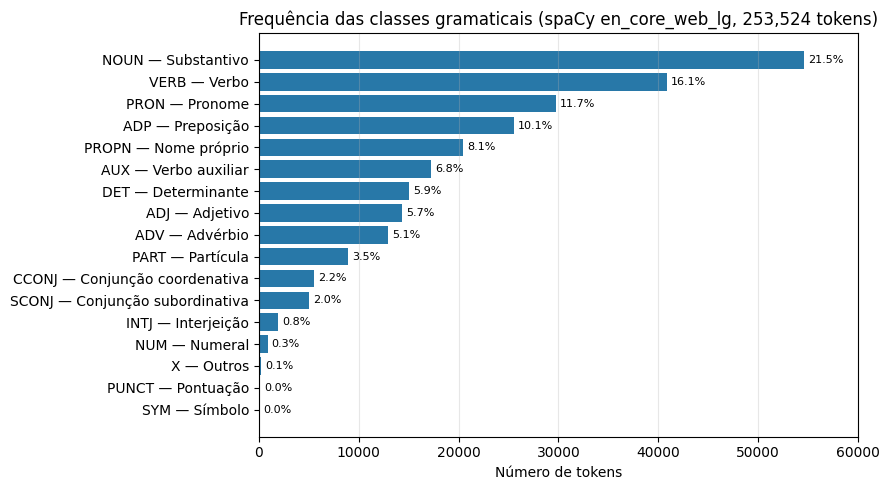

In [25]:
nomes_pos = {
    'NOUN': 'Substantivo', 'PROPN': 'Nome próprio', 'VERB': 'Verbo', 'AUX': 'Verbo auxiliar',
    'ADJ': 'Adjetivo', 'ADV': 'Advérbio', 'PRON': 'Pronome', 'DET': 'Determinante',
    'ADP': 'Preposição', 'CCONJ': 'Conjunção coordenativa', 'SCONJ': 'Conjunção subordinativa',
    'PART': 'Partícula', 'NUM': 'Numeral', 'INTJ': 'Interjeição', 'PUNCT': 'Pontuação',
    'SYM': 'Símbolo', 'X': 'Outros',
}
frequencias_pos = pos_tokens['pos'].value_counts().rename_axis('etiqueta').reset_index(name='frequencia')
frequencias_pos.insert(1, 'classe_gramatical', frequencias_pos['etiqueta'].map(nomes_pos))
frequencias_pos['percentual'] = frequencias_pos['frequencia'] / frequencias_pos['frequencia'].sum() * 100
frequencias_pos.to_csv(pasta_q5 / 'frequencias_pos.csv', index=False, encoding='utf-8-sig')
display(frequencias_pos.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
ordem = frequencias_pos.iloc[::-1]
barras = ax.barh(ordem['etiqueta'] + ' — ' + ordem['classe_gramatical'], ordem['frequencia'], color='#2878A8')
ax.bar_label(barras, labels=[f'{p:.1f}%' for p in ordem['percentual']], padding=3, fontsize=8)
ax.set_xlabel('Número de tokens')
ax.set_title(f'Frequência das classes gramaticais (spaCy {MODELO_SPACY}, {len(pos_tokens):,} tokens)')
ax.grid(axis='x', alpha=0.3)
ax.margins(x=0.1)
fig.tight_layout()
fig.savefig(pasta_q5 / 'frequencias_pos.png', dpi=160)
plt.show()

**Análise das frequências gramaticais (5b).** Foram etiquetados **253524 tokens** nos 14.640 tweets pré-processados. As três classes mais frequentes foram **NOUN: 54546 (21,52%); VERB: 40878 (16,12%); PRON: 29761 (11,74%)**.

As frequências representam tokens, não documentos: um tweet pode contribuir várias vezes para uma classe. A distribuição reúne conteúdo lexical (substantivos, verbos, adjetivos) e palavras funcionais (pronomes, preposições e determinantes). As proporções refletem também o estilo informal dos tweets e o pré-processamento: pontuação e números foram removidos antes da aplicação da spaCy.

As etiquetas são predições automáticas. Nomes de contas, abreviações e palavras concatenadas pela remoção da pontuação podem receber classes incorretas. Os exemplos da 5a permitem conferir esses casos; a tabela de frequências não deve ser interpretada como anotação linguística manual.

**c) Escolha do tipo de entidade.** Para seguir a recomendação do enunciado, contamos, para cada tipo, quantos tweets têm ao menos uma entidade dele e quantos têm duas ou mais entidades distintas (o que gera arestas no grafo da 5d).

**Normalização das entidades:** o mesmo lugar aparece com grafias diferentes, então removemos `#`, `@`, o artigo inicial `the` e o possessivo `'s`, e unificamos variações de maiúsculas e minúsculas pela forma mais frequente (`DENVER`, `denver` e `Denver` viram `Denver`). Siglas e nomes diferentes do mesmo lugar (`NYC` e `New York`) não são unidos, para não introduzir escolhas manuais.

In [26]:
def normalizar_entidade(texto):
    texto = ' '.join(texto.replace('’', "'").split()).lstrip('#@')
    if texto.lower().startswith('the '):
        texto = texto[4:]
    if texto.lower().endswith("'s"):
        texto = texto[:-2]
    return texto.strip(' -')

entidades_brutas = [[(normalizar_entidade(e.text), e.label_) for e in doc.ents] for doc in docs_q5]

linhas = []
for tipo in sorted({rotulo for ents in entidades_brutas for _, rotulo in ents}):
    por_doc = [{t.casefold() for t, r in ents if r == tipo and t} for ents in entidades_brutas]
    mencoes = sum(r == tipo for ents in entidades_brutas for _, r in ents)
    com_tipo = sum(len(s) >= 1 for s in por_doc)
    com_dois = sum(len(s) >= 2 for s in por_doc)
    linhas.append({'tipo': tipo, 'descricao': spacy.explain(tipo), 'mencoes': mencoes,
                   'entidades_distintas': len(set().union(*por_doc)), 'tweets_com_o_tipo': com_tipo,
                   'tweets_com_2_ou_mais': com_dois,
                   'pct_com_2_ou_mais': 100 * com_dois / com_tipo if com_tipo else 0.0})
tipos_entidade = pd.DataFrame(linhas).sort_values('tweets_com_2_ou_mais', ascending=False).reset_index(drop=True)
tipos_entidade.to_csv(pasta_q5 / 'tipos_entidade.csv', index=False, encoding='utf-8-sig')
display(tipos_entidade.round(1))

,tipo,descricao,mencoes,entidades_distintas,tweets_com_o_tipo,tweets_com_2_ou_mais,pct_com_2_ou_mais
0,ORG,"Companies, agencies, institutions, etc.",7085,1743,6065,824,13.6
1,GPE,"Countries, cities, states",2202,440,1792,332,18.5
2,DATE,Absolute or relative dates or periods,1861,351,1710,123,7.2
3,TIME,Times smaller than a day,1776,329,1651,99,6.0
4,PERSON,"People, including fictional",1381,733,1312,61,4.6
5,CARDINAL,Numerals that do not fall under another type,480,46,454,19,4.2
6,NORP,Nationalities or religious or political groups,146,49,135,9,6.7
7,ORDINAL,"""first"", ""second"", etc.",310,7,296,6,2.0
8,FAC,"Buildings, airports, highways, bridges, etc.",189,118,184,5,2.7
9,PRODUCT,"Objects, vehicles, foods, etc. (not services)",250,124,246,3,1.2


**Escolha e limitações (5c).** Escolhemos `GPE` (países, cidades e estados), porque a base contém relatos de viagens, origens e destinos. A tabela acima permite verificar quantos tweets contêm pelo menos duas entidades distintas desse tipo, condição necessária para gerar arestas. A escolha considera a interpretação geográfica das coocorrências, e não apenas o tipo com maior número absoluto de menções.

O reconhecimento é automático e pode confundir nomes de companhias, aeroportos e localidades, especialmente após converter os textos para minúsculas. Unificamos grafias por caixa, mas não fazemos resolução completa de entidades: siglas, apelidos e nomes completos do mesmo lugar podem continuar em nós diferentes. Os exemplos abaixo tornam essas limitações verificáveis.

**Resultado observado:** GPE teve **2202 menções**, **440 entidades distintas**, **1792 tweets com ao menos uma entidade** e **332 com duas ou mais** (18,5% entre os tweets que têm GPE). ORG apareceu com pelo menos duas entidades distintas em 824 tweets; GPE foi escolhido pela interpretação de origens, destinos e localidades, e não por maximizar essa contagem.

In [27]:
TIPO_ENTIDADE = 'GPE'

# Forma de exibição de cada entidade: a grafia mais frequente entre as que só diferem em maiúsculas.
grafias = Counter(t for ents in entidades_brutas for t, r in ents if r == TIPO_ENTIDADE and t)
forma_canonica = {}
for grafia, _ in grafias.most_common():
    forma_canonica.setdefault(grafia.casefold(), grafia)

entidades_por_doc = [sorted({forma_canonica[t.casefold()] for t, r in ents if r == TIPO_ENTIDADE and t})
                     for ents in entidades_brutas]
mencoes_q5 = pd.DataFrame(
    [(i, base.loc[i, 'tweet_id'], e.text, forma_canonica[normalizar_entidade(e.text).casefold()], e.start_char, e.end_char)
     for i, doc in enumerate(docs_q5) for e in doc.ents
     if e.label_ == TIPO_ENTIDADE and normalizar_entidade(e.text)],
    columns=['indice_base', 'tweet_id', 'trecho_reconhecido', 'entidade', 'inicio', 'fim'])
mencoes_q5['texto_processado'] = mencoes_q5['indice_base'].map(base['texto_processado'])
mencoes_q5.to_csv(pasta_q5 / f'entidades_{TIPO_ENTIDADE}.csv', index=False, encoding='utf-8-sig')

freq_entidades = Counter(e for ents in entidades_por_doc for e in ents)  # número de tweets com a entidade
pd.DataFrame(freq_entidades.most_common(), columns=['entidade', 'tweets']).to_csv(
    pasta_q5 / 'frequencias_entidades.csv', index=False, encoding='utf-8-sig')
print(f'{TIPO_ENTIDADE}: {len(mencoes_q5)} menções, {len(freq_entidades)} entidades distintas, '
      f'{sum(len(e) > 0 for e in entidades_por_doc)} tweets com ao menos uma')
print('\n20 entidades mais frequentes (número de tweets):')
display(pd.DataFrame(freq_entidades.most_common(20), columns=['entidade', 'tweets']))

print('Exemplos de tweets com duas ou mais entidades:')
for i in [i for i, e in enumerate(entidades_por_doc) if len(e) >= 2][:6]:
    print(f'  [{i}] {entidades_por_doc[i]} <- {textos_q5[i]!r}')

GPE: 2202 menções, 440 entidades distintas, 1792 tweets com ao menos uma

20 entidades mais frequentes (número de tweets):


,entidade,tweets
0,dfw,119
1,dallas,78
2,boston,74
3,chicago,73
4,denver,67
5,sfo,63
6,charlotte,56
7,newark,50
8,houston,49
9,philly,48


Exemplos de tweets com duas ou mais entidades:
  [34] ['america', 'hawaii'] <- 'virginamerica this is great news america could start flights to hawaii by end of year via pacificbiznews'
  [40] ['hollywood', 'los angeles'] <- 'virginamerica view of downtown los angeles the hollywood sign and beyond that rain in the mountains'
  [44] ['dallas', 'seattle'] <- 'virginamerica are flights leaving dallas for seattle on time feb'
  [54] ['dallas', 'la'] <- 'virginamerica will flights be leaving dallas for la on february'
  [67] ['la', 'nyc'] <- 'virginamerica hi virgin im on hold for minutes are there any earlier flights from la to nyc tonight earlier than'
  [132] ['cabo san lucas', 'sfo'] <- 'virginamerica has flight number from sfo to cabo san lucas arrived yet'


**d) Grafo de coocorrência.** Cada entidade distinta é um nó, com o número de tweets em que aparece. Para cada tweet, cada par de entidades distintas do tweet soma 1 ao peso da aresta entre elas, de modo que o peso é o número de tweets em que o par aparece junto. O grafo completo é salvo em `grafo_entidades.graphml` e as arestas em `arestas_entidades.csv`. Como o grafo completo fica poluído, a figura mostra só as 30 entidades mais frequentes e as arestas entre elas; a espessura das arestas é proporcional ao peso e o tamanho dos nós à frequência.

Grafo completo: 440 nós, 367 arestas, 200 nós isolados (entidades que nunca aparecem com outra)

15 arestas de maior peso:


,entidade_1,entidade_2,peso
0,dallas,austin,5
1,dallas,la,4
2,houston,austin,4
3,dallas,jacksonville fl,4
4,columbus,oakland,4
5,charlotte,atlanta,3
6,dallas,ohio,3
7,charlotte,nc,3
8,boston,seattle,3
9,philly,orlando,3


Subgrafo das 30 entidades mais frequentes: 78 arestas, 2 nós sem aresta entre as 30


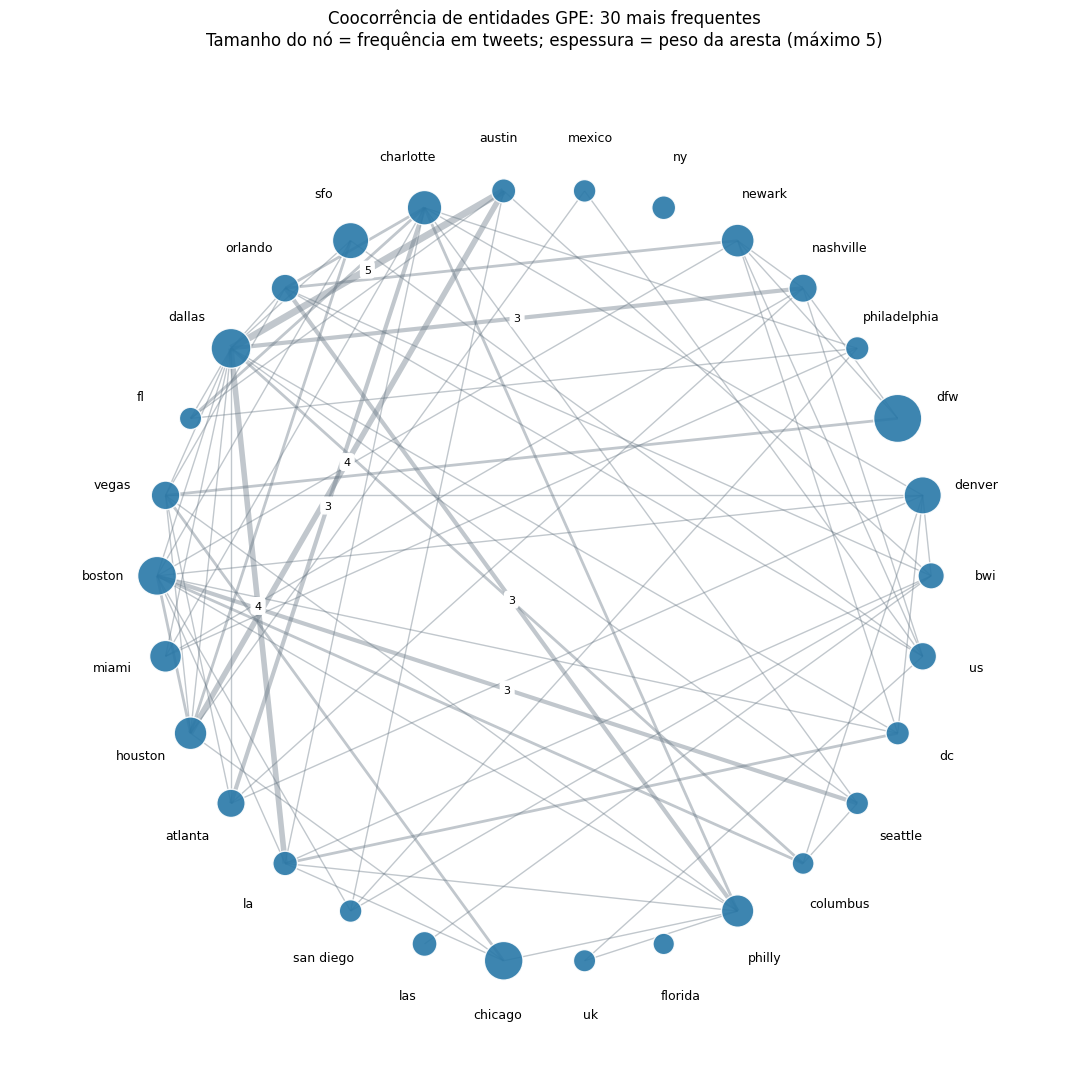

In [2]:
G = nx.Graph()
for entidade, freq in freq_entidades.items():
    G.add_node(entidade, frequencia=freq)
for ents in entidades_por_doc:
    for a, b in itertools.combinations(ents, 2):
        if G.has_edge(a, b):
            G[a][b]['weight'] += 1
        else:
            G.add_edge(a, b, weight=1)

nx.write_graphml(G, pasta_q5 / 'grafo_entidades.graphml')
arestas_q5 = pd.DataFrame([(a, b, d['weight']) for a, b, d in G.edges(data=True)],
                          columns=['entidade_1', 'entidade_2', 'peso']).sort_values('peso', ascending=False)
arestas_q5.to_csv(pasta_q5 / 'arestas_entidades.csv', index=False, encoding='utf-8-sig')
print(f'Grafo completo: {G.number_of_nodes()} nós, {G.number_of_edges()} arestas, '
      f'{nx.number_of_isolates(G)} nós isolados (entidades que nunca aparecem com outra)')
print('\n15 arestas de maior peso:')
display(arestas_q5.head(15).reset_index(drop=True))

N_NOS = 30
principais = [e for e, _ in freq_entidades.most_common(N_NOS)]
H = G.subgraph(principais).copy()
print(f'Subgrafo das {N_NOS} entidades mais frequentes: {H.number_of_edges()} arestas, '
      f'{nx.number_of_isolates(H)} nós sem aresta entre as {N_NOS}')

pesos = np.array([d['weight'] for _, _, d in H.edges(data=True)])
frequencias = np.array([H.nodes[n]['frequencia'] for n in H.nodes])
# Disposição circular: nós isolados não comprimem a componente conectada.
# A posição é apenas visual e não representa distância geográfica.
posicoes = nx.circular_layout(H)
posicoes_rotulos = {n: 1.14 * p for n, p in posicoes.items()}

fig, ax = plt.subplots(figsize=(13, 11))
nx.draw_networkx_edges(H, posicoes, ax=ax, width=5 * pesos / pesos.max(),
                       edge_color='#657582', alpha=0.4)
nx.draw_networkx_nodes(H, posicoes, ax=ax, node_size=1100 * frequencias / frequencias.max() + 100,
                       node_color='#2878A8', alpha=0.9, edgecolors='white', linewidths=1)
nx.draw_networkx_labels(H, posicoes_rotulos, ax=ax, font_size=9,
                        bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.9, lw=0))
# Rotula apenas os maiores pesos; todas as arestas mantêm espessura proporcional ao peso.
rotulos_fortes = {(a, b): d['weight'] for a, b, d in H.edges(data=True)
                  if d['weight'] >= max(3, np.percentile(pesos, 90))}
nx.draw_networkx_edge_labels(H, posicoes, edge_labels=rotulos_fortes,
                            ax=ax, font_size=8, rotate=False)
ax.set_title(f'Coocorrência de entidades {TIPO_ENTIDADE}: {N_NOS} mais frequentes\n'
             f'Tamanho do nó = frequência em tweets; espessura = peso da aresta (máximo {pesos.max()})',
             fontsize=12, pad=20)
ax.set_xlim(-1.38, 1.38)
ax.set_ylim(-1.30, 1.30)
ax.set_aspect('equal')
ax.axis('off')
fig.tight_layout()
fig.savefig(pasta_q5 / 'grafo_entidades.png', dpi=150)
plt.show()


**Resultado do grafo (5d).** O grafo completo tem **440 nós**, **367 arestas** e **200 nós isolados**. Entre as arestas de maior peso estão: dallas — austin (peso 5); dallas — la (peso 4); austin — houston (peso 4).

**Análise do grafo (5d).** Uma aresta representa dois nomes de lugares mencionados no mesmo tweet; ela não comprova a existência de uma rota aérea entre esses lugares. Como cada documento usa um conjunto de entidades distintas, repetir um nome no mesmo tweet não aumenta o peso. Assim, cada unidade de peso corresponde a um tweet que menciona o par.

Os nós isolados pertencem ao grafo completo, mas não geram relações de coocorrência. A figura limita a visualização às 30 entidades mais frequentes; uma entidade pode ficar isolada nesse recorte mesmo tendo ligações com entidades omitidas. O arquivo GraphML e a tabela de arestas preservam o grafo completo.

Rótulos incorretos do reconhecedor e variantes não unificadas afetam a estrutura. A espessura das arestas informa frequência de coocorrência e o tamanho dos nós informa frequência em documentos; a disposição circular serve para manter os rótulos legíveis, inclusive os nós isolados, e não representa coordenadas geográficas.

**Efeito do pré-processamento:** na amostra de 2.000 tweets, o modelo reconheceu 2882 entidades no texto original e 2193 no pré-processado. A diferença mostra sensibilidade à forma de entrada, mas não mede acurácia: seria necessário um conjunto anotado para quantificar erros e acertos. Os resultados principais desta questão usam a versão pré-processada exigida pela lista.

# Verificação da entrega e ambiente

A célula final verifica os arquivos gerados e algumas propriedades dos resultados. As versões registradas descrevem o ambiente desta execução.

In [29]:
import json
import platform
from importlib.metadata import version

assert len(consultas) == 5 and not (set(consultas) & todos_tokens)
assert len(linhas_3c) == 15
assert len(documentos_3b) == sum(linha['n_documentos'] for linha in linhas_resumo)
assert pos_tokens['indice_base'].nunique() == len(base)
assert int(frequencias_pos['frequencia'].sum()) == len(pos_tokens)
assert G.number_of_nodes() == len(freq_entidades)
assert sum(d['weight'] for _, _, d in G.edges(data=True)) == sum(
    len(ents) * (len(ents) - 1) // 2 for ents in entidades_por_doc)
assert len(cv_q4) == 8 * 5

esperados = {
    'questao_1': ['silhueta_tfidf.csv', 'silhueta_nmf.csv', 'grupos.csv', 'silhueta_tfidf.png', 'silhueta_nmf.png'],
    'questao_2': ['melhores_projecoes.png', 'coordenadas_melhores_projecoes.csv', 'confiabilidade_perplexidade.csv',
                  'confiabilidade_perplexidade.png', 'tsne_tfidf_perplexity30.png', 'tsne_tfidf_perplexidades.png'],
    'questao_3': ['palavras_parecidas.csv', 'documentos_3b.csv', 'documentos_3b.html', 'documentos_3c.csv'],
    'questao_4': ['comparacao_modelos.csv', 'validacao_cruzada.csv', 'predicoes_teste.csv',
                  'historico_lstm.csv', 'historico_conv1d.csv', 'curvas_aprendizado.png',
                  'matrizes_confusao.png', 'matriz_confusao_lstm.csv', 'matriz_confusao_conv1d.csv', 'comparacao_f1_macro.png'],
    'questao_5': ['pos_tokens.csv.gz', 'frequencias_pos.csv', 'frequencias_pos.png', 'tipos_entidade.csv',
                  'entidades_GPE.csv', 'frequencias_entidades.csv', 'arestas_entidades.csv',
                  'grafo_entidades.graphml', 'grafo_entidades.png', 'efeito_preprocessamento.csv'],
}
for questao, arquivos in esperados.items():
    for nome in arquivos:
        arquivo = pasta_resultados / questao / nome
        assert arquivo.is_file() and arquivo.stat().st_size > 0, str(arquivo)

ambiente = {'python': platform.python_version(), 'sistema': platform.system(),
            'bibliotecas': {p: version(p) for p in [
                'numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'torch', 'spacy',
                'networkx', 'nbformat', 'nbclient', 'ipykernel']},
            'modelo_spacy': {'nome': MODELO_SPACY, 'versao': nlp.meta['version']},
            'semente': SEMENTE, 'documentos': len(base), 'word2vec_limite': LIMITE_PALAVRAS}
(pasta_resultados / 'ambiente_execucao.json').write_text(
    json.dumps(ambiente, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Verificações concluídas: cinco questões, arquivos presentes e resultados consistentes.')
print(json.dumps(ambiente, ensure_ascii=False, indent=2))


Verificações concluídas: cinco questões, arquivos presentes e resultados consistentes.
{
  "python": "3.10.0",
  "sistema": "Windows",
  "bibliotecas": {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "scipy": "1.15.3",
    "scikit-learn": "1.7.2",
    "matplotlib": "3.10.9",
    "torch": "2.14.1+cpu",
    "spacy": "3.8.16",
    "networkx": "3.4.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.3.0"
  },
  "modelo_spacy": {
    "nome": "en_core_web_lg",
    "versao": "3.8.0"
  },
  "semente": 42,
  "documentos": 14640,
  "word2vec_limite": 500000
}
